# COURSE PROJECT: PROGRAMMING FOUNDATIONS FOR DATA ANALYSIS AND VISUALIZATION
**Semester 261 – Academic Year 2026–2027** | **Instructor:** Lê Thành Sách

---
## PART 3: TIME SERIES DATA
### Topic: 24-Hour-Ahead PM2.5 Forecasting — Hanoi vs Ho Chi Minh City

- **Group:** IndexError
- **Member in charge:** Nguyễn Văn Hoàng Khang – 2570754

**Problem.** At time $t$, using the PM2.5 history and the current weather, forecast the PM2.5 concentration
at time $t + 24h$ (the same hour tomorrow). This is a **time series regression** problem.

**Why compare two cities?** Hanoi (four seasons, winter temperature inversion) and Ho Chi Minh City (HCMC; wet/dry seasons)
have different pollution mechanisms. We apply **the same pipeline** to each city **independently** (no merging) to answer:
*how much does machine learning improve over a naive baseline in each city, and which city is harder to forecast?*

## 0. ENVIRONMENT SETUP

In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, TransformerMixin, RegressorMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 11

RANDOM_STATE = 42
HORIZON = 24            # forecast 24 hours ahead
WHO_24H = 15            # WHO 2021 guideline for 24-hour mean PM2.5 (µg/m³)
CITY_COLORS = {'Hanoi': '#d62728', 'HCMC': '#1f77b4'}
import sklearn
print(f'Environment ready! (scikit-learn {sklearn.__version__}, pandas {pd.__version__})')

Environment ready! (scikit-learn 1.9.1, pandas 3.0.5)


## 1. DATASET DESCRIPTION

### 1.1. Data sources (self-collected)
The data was **collected through public APIs** with the script `scripts/crawl_air_quality.py`:

| Component | Source | Notes |
|---|---|---|
| PM2.5 – Hanoi | [OpenAQ v3](https://openaq.org) – station *46 Luu Quang Vu* (Hanoi Air Quality Monitoring Network, sensor 7772032) | City monitoring station, **has real gaps** |
| PM2.5 – HCMC | OpenAQ v3 – station *CMT8* (AirGradient, sensor 11357424) | Low-cost sensor |
| Weather | [Open-Meteo Historical Weather API](https://open-meteo.com) | Temperature, humidity, precipitation, wind, pressure, cloud cover |

- **Period:** 01/12/2024 – 30/09/2026 (22 months, 16,056 hours per city), Vietnam local time (UTC+7).
- A complete hourly time grid is built: hours with no measurement become `NaN`.

| Column | Type | Meaning |
|---|---|---|
| `datetime` | datetime | Timestamp (local time) |
| `city` | categorical | City |
| `temperature_2m` | numerical | Temperature at 2 m (°C) |
| `relative_humidity_2m` | numerical | Relative humidity (%) |
| `precipitation` | numerical | Precipitation (mm) |
| `wind_speed_10m` | numerical | Wind speed at 10 m (km/h) |
| `wind_direction_10m` | numerical (angle) | Wind direction (degrees) → converted to a **categorical** 8-sector feature |
| `surface_pressure` | numerical | Surface pressure (hPa) |
| `cloud_cover` | numerical | Cloud cover (%) |
| `pm25` | numerical | PM2.5 concentration (µg/m³) — **the variable to forecast** |
| `pm25_source` | categorical | PM2.5 source (`openaq`, or `open-meteo` if the crawler had to fall back) |

### 1.2. Loading the data
The CSV files are read locally; on Colab, if they are not found, they are downloaded from GitHub (**set `GITHUB_RAW_BASE`** to the group's repo).

In [2]:
GITHUB_RAW_BASE = 'https://raw.githubusercontent.com/perckgg/NTLT/main/03_TimeSeries/data/timeseries'
CITY_FILES = {'Hanoi': 'air_quality_hanoi.csv', 'HCMC': 'air_quality_hcmc.csv'}
LOCAL_DIRS = ['data/timeseries', '../data/timeseries', '/content/data/timeseries', '/content']


def load_city_data(filename):
    for d in LOCAL_DIRS:
        path = os.path.join(d, filename)
        if os.path.exists(path):
            return pd.read_csv(path, parse_dates=['datetime'])
    return pd.read_csv(f'{GITHUB_RAW_BASE}/{filename}', parse_dates=['datetime'])


raw = {city: load_city_data(f).set_index('datetime').sort_index().assign(city=city)
       for city, f in CITY_FILES.items()}
for city, df in raw.items():
    print(f'{city}: {df.shape[0]:,} rows × {df.shape[1]} columns | '
          f'{df.index.min():%Y-%m-%d} → {df.index.max():%Y-%m-%d} | PM2.5 source: {", ".join(df.pm25_source.unique())}')
raw['Hanoi'].head()

Hanoi: 16,056 rows × 10 columns | 2024-12-01 → 2026-09-30 | PM2.5 source: openaq
HCMC: 16,056 rows × 10 columns | 2024-12-01 → 2026-09-30 | PM2.5 source: openaq


,city,temperature_2m,relative_humidity_2m,precipitation,wind_speed_10m,wind_direction_10m,surface_pressure,cloud_cover,pm25,pm25_source
datetime,,,,,,,,,,
2024-12-01 00:00:00,Hanoi,17.2,82,0.0,3.3,158,1012.9,94,39.5,openaq
2024-12-01 01:00:00,Hanoi,16.8,85,0.0,2.6,164,1012.7,97,41.6,openaq
2024-12-01 02:00:00,Hanoi,16.5,86,0.0,0.8,117,1012.0,94,38.8,openaq
2024-12-01 03:00:00,Hanoi,15.5,91,0.0,1.8,37,1011.7,93,43.0,openaq
2024-12-01 04:00:00,Hanoi,14.8,95,0.0,3.3,45,1011.4,86,41.9,openaq


### 1.3. Descriptive statistics
The WHO guideline of 15 µg/m³ is defined for the **24-hour mean**, so it is compared with **daily means**, not with single hours.
A daily mean is computed only for days with at least 18 of 24 hours measured (75% completeness, the usual rule for daily averages);
other days are left out rather than averaged over a few hours.

In [3]:
MIN_HOURS_PER_DAY = 18   # 75% of 24 hours


def daily_means(s, min_hours=MIN_HOURS_PER_DAY):
    """Daily mean of an hourly series; NaN for days with fewer than `min_hours` measured hours."""
    days = s.resample('D')
    return days.mean().where(days.count() >= min_hours)


raw['Hanoi'].info()
summary = pd.concat({city: df['pm25'].describe() for city, df in raw.items()}, axis=1).T
summary['missing_rate'] = [df['pm25'].isna().mean() for df in raw.values()]
daily = {city: daily_means(df['pm25']).dropna() for city, df in raw.items()}
summary['valid days'] = [len(d) for d in daily.values()]
summary['share of days > WHO 24h'] = [(d > WHO_24H).mean() for d in daily.values()]
display(summary.round(3))
display(pd.concat({city: df.describe().T for city, df in raw.items()}).round(2))

<class 'pandas.DataFrame'>
DatetimeIndex: 16056 entries, 2024-12-01 00:00:00 to 2026-09-30 23:00:00
Data columns (total 10 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   city                  16056 non-null  str    
 1   temperature_2m        16056 non-null  float64
 2   relative_humidity_2m  16056 non-null  int64  
 3   precipitation         16056 non-null  float64
 4   wind_speed_10m        16056 non-null  float64
 5   wind_direction_10m    16056 non-null  int64  
 6   surface_pressure      16056 non-null  float64
 7   cloud_cover           16056 non-null  int64  
 8   pm25                  10787 non-null  float64
 9   pm25_source           16056 non-null  str    
dtypes: float64(5), int64(3), str(2)
memory usage: 1.3 MB


,count,mean,std,min,25%,50%,75%,max,missing_rate,valid days,share of days > WHO 24h
Hanoi,10787.0,31.669,20.605,0.0,17.8,26.0,39.1,332.0,0.328,389,0.913
HCMC,14711.0,32.138,16.326,2.5,20.9,29.5,39.4,171.0,0.084,613,0.982


count     mean    std     min     25%     50%  \
Hanoi temperature_2m        16056.0    24.38   5.46     7.4    20.5    25.3   
      relative_humidity_2m  16056.0    79.47  14.59    26.0    70.0    82.0   
      precipitation         16056.0     0.27   1.10     0.0     0.0     0.0   
      wind_speed_10m        16056.0     8.73   4.54     0.0     5.2     8.4   
      wind_direction_10m    16056.0   144.98  96.24     1.0    75.0   137.0   
      surface_pressure      16056.0  1008.61   7.48   986.5  1002.4  1008.0   
      cloud_cover           16056.0    71.79  38.18     0.0    35.0    98.0   
      pm25                  10787.0    31.67  20.61     0.0    17.8    26.0   
HCMC  temperature_2m        16056.0    27.68   2.95    18.0    25.5    27.0   
      relative_humidity_2m  16056.0    77.85  15.88    23.0    68.0    82.0   
      precipitation         16056.0     0.25   1.00     0.0     0.0     0.0   
      wind_speed_10m        16056.0     7.03   3.79     0.0     4.1     6.6   
      wind_direction_10m    16056.0   188.86  88.39     1.0   127.0   188.0   
      surface_pressure      16056.0  1008.27   2.27  1001.1  1006.7  1008.2   
      cloud_cover           16056.0    75.97  34.31     0.0    55.0    98.0   
      pm25                  14711.0    32.14  16.33     2.5    20.9    29.5   

                               75%     max  
Hanoi temperature_2m          28.2    38.6  
      relative_humidity_2m    92.0   100.0  
      precipitation            0.1    28.8  
      wind_speed_10m          11.7    34.4  
      wind_direction_10m     173.0   360.0  
      surface_pressure      1014.7  1032.1  
      cloud_cover            100.0   100.0  
      pm25                    39.1   332.0  
HCMC  temperature_2m          29.6    39.1  
      relative_humidity_2m    91.0   100.0  
      precipitation            0.1    22.2  
      wind_speed_10m           9.6    23.8  
      wind_direction_10m     251.0   360.0  
      surface_pressure      1009.7  1016.3  
      cloud_cover            100.0   100.0  
      pm25                    39.4   171.0

### 1.4. Time series visualization
**Figure 1 – Daily mean PM2.5** in both cities against the WHO 24-hour guideline (15 µg/m³).

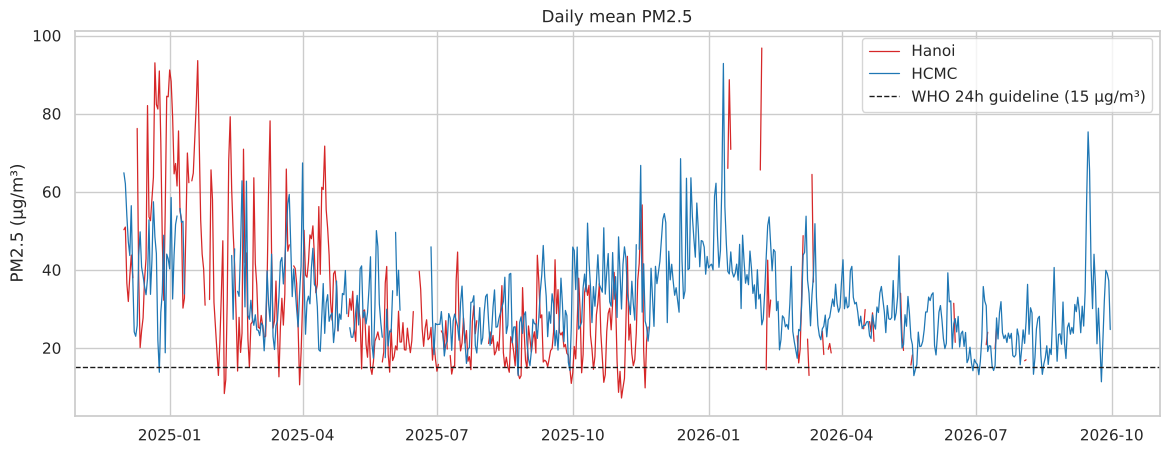

In [4]:
fig, ax = plt.subplots(figsize=(14, 5))
for city, df in raw.items():
    d = daily_means(df['pm25'])          # NaN (gap in the line) on days with < 18 measured hours
    ax.plot(d.index, d, label=city, color=CITY_COLORS[city], lw=0.9)
ax.axhline(WHO_24H, color='k', ls='--', lw=1, label='WHO 24h guideline (15 µg/m³)')
ax.set(title='Daily mean PM2.5', ylabel='PM2.5 (µg/m³)')
ax.legend()
plt.show()

**Figure 2 – Distribution of hourly PM2.5** and **Figure 3 – Monthly boxplots** (seasonality).

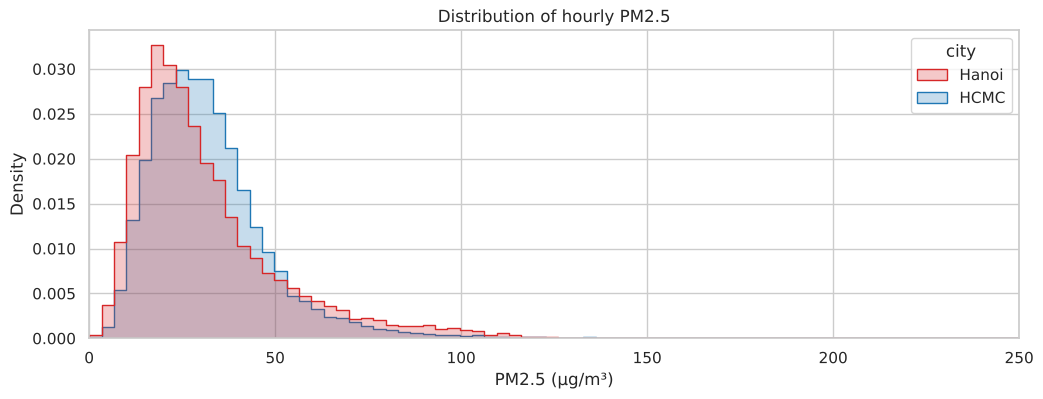

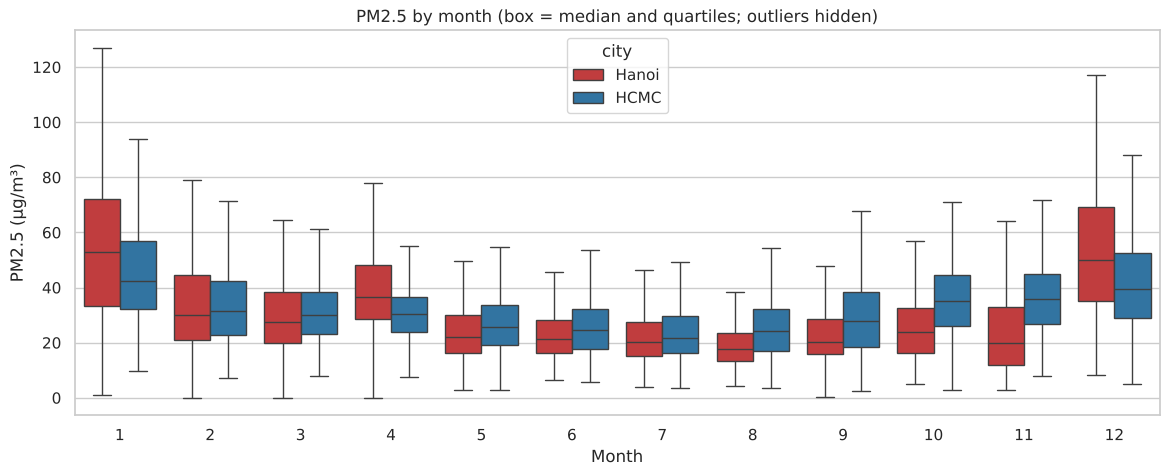

Hourly PM2.5 by calendar month (mean and median over all years, µg/m³):


mean       median      
city   HCMC Hanoi   HCMC Hanoi
month                         
1      46.2  55.0   42.4  52.8
2      35.0  36.1   31.4  30.1
3      32.5  31.5   30.2  27.6
4      31.2  39.8   30.2  36.7
5      27.5  24.2   25.7  22.2
6      26.3  23.6   24.6  21.5
7      23.5  22.3   21.7  20.4
8      25.2  19.4   24.1  17.6
9      30.1  24.0   27.7  20.4
10     36.7  25.2   35.3  24.0
11     37.5  24.2   35.7  20.0
12     42.4  53.3   39.4  50.0

In [5]:
plot_df = pd.concat([df[['pm25']].assign(city=city) for city, df in raw.items()])
plot_df['month'] = plot_df.index.month
plot_df['hour'] = plot_df.index.hour
plot_df = plot_df.reset_index(drop=True)

fig, ax = plt.subplots(figsize=(12, 4))
sns.histplot(data=plot_df, x='pm25', hue='city', bins=100, element='step', stat='density',
             common_norm=False, palette=CITY_COLORS, ax=ax)
ax.set(title='Distribution of hourly PM2.5', xlabel='PM2.5 (µg/m³)', xlim=(0, 250))
plt.show()

fig, ax = plt.subplots(figsize=(14, 5))
sns.boxplot(data=plot_df, x='month', y='pm25', hue='city', palette=CITY_COLORS, showfliers=False, ax=ax)
ax.set(title='PM2.5 by month (box = median and quartiles; outliers hidden)', xlabel='Month', ylabel='PM2.5 (µg/m³)')
plt.show()

monthly = plot_df.groupby(['city', 'month'])['pm25'].agg(['mean', 'median']).round(1).unstack('city')
print('Hourly PM2.5 by calendar month (mean and median over all years, µg/m³):')
display(monthly)

**Figure 4 – Daily cycle:** mean PM2.5 by hour of day, split into the dry/cool half-year (Nov–Apr) and the wet/hot half-year (May–Oct).
Only **days with at least 18 measured hours** are used. Reason: from November 2025 the Hanoi station rarely reports in the afternoon,
so a plain mean by hour would average the afternoon hours over *different days* (mostly the cleaner, earlier period) than the night hours,
and the shape of the curve would reflect *which days have data* instead of the real daily cycle.

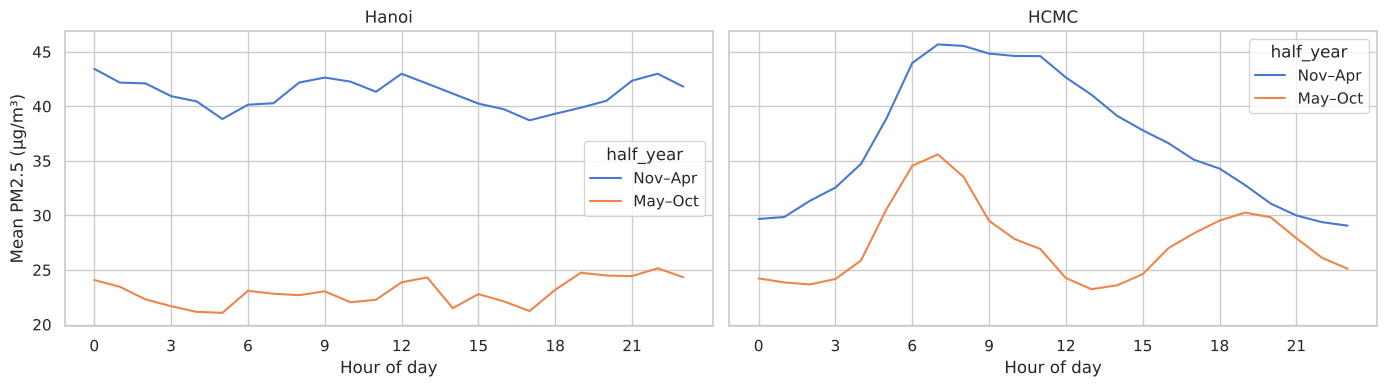

Hanoi May–Oct (189 complete days): highest mean at 22h (25.2 µg/m³), lowest at 5h (21.1 µg/m³)
Hanoi Nov–Apr (200 complete days): highest mean at 0h (43.4 µg/m³), lowest at 17h (38.7 µg/m³)
HCMC May–Oct (315 complete days): highest mean at 7h (35.6 µg/m³), lowest at 13h (23.2 µg/m³)
HCMC Nov–Apr (298 complete days): highest mean at 7h (45.7 µg/m³), lowest at 23h (29.1 µg/m³)


In [6]:
def complete_days_only(s, min_hours=MIN_HOURS_PER_DAY):
    """Keep only the hours of days that have at least `min_hours` measured hours."""
    measured_per_day = s.groupby(s.index.floor('D')).transform('count')
    return s[measured_per_day >= min_hours]


cycle_df = pd.concat([complete_days_only(df['pm25']).to_frame().assign(city=city) for city, df in raw.items()])
cycle_df['hour'] = cycle_df.index.hour
cycle_df['half_year'] = np.where(cycle_df.index.month.isin([11, 12, 1, 2, 3, 4]), 'Nov–Apr', 'May–Oct')

fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax, city in zip(axes, CITY_FILES):
    g = cycle_df[cycle_df.city == city]
    sns.lineplot(data=g, x='hour', y='pm25', hue='half_year', errorbar=None, ax=ax)
    ax.set(title=city, xlabel='Hour of day', ylabel='Mean PM2.5 (µg/m³)', xticks=range(0, 24, 3))
plt.tight_layout()
plt.show()

for city in CITY_FILES:
    for half, g in cycle_df[cycle_df.city == city].groupby('half_year'):
        by_hour = g.groupby('hour')['pm25'].mean()
        print(f'{city} {half} ({g.index.floor("D").nunique()} complete days): highest mean at {by_hour.idxmax()}h '
              f'({by_hour.max():.1f} µg/m³), lowest at {by_hour.idxmin()}h ({by_hour.min():.1f} µg/m³)')

**Figure 5 – Spearman correlation matrix** between PM2.5 and the weather variables, per city.

Hanoi – Spearman correlation of PM2.5 with: {'temperature_2m': -0.26, 'relative_humidity_2m': -0.16, 'precipitation': -0.29, 'wind_speed_10m': -0.15, 'surface_pressure': 0.28, 'cloud_cover': -0.28}


HCMC – Spearman correlation of PM2.5 with: {'temperature_2m': -0.03, 'relative_humidity_2m': -0.08, 'precipitation': -0.14, 'wind_speed_10m': -0.38, 'surface_pressure': 0.25, 'cloud_cover': -0.04}


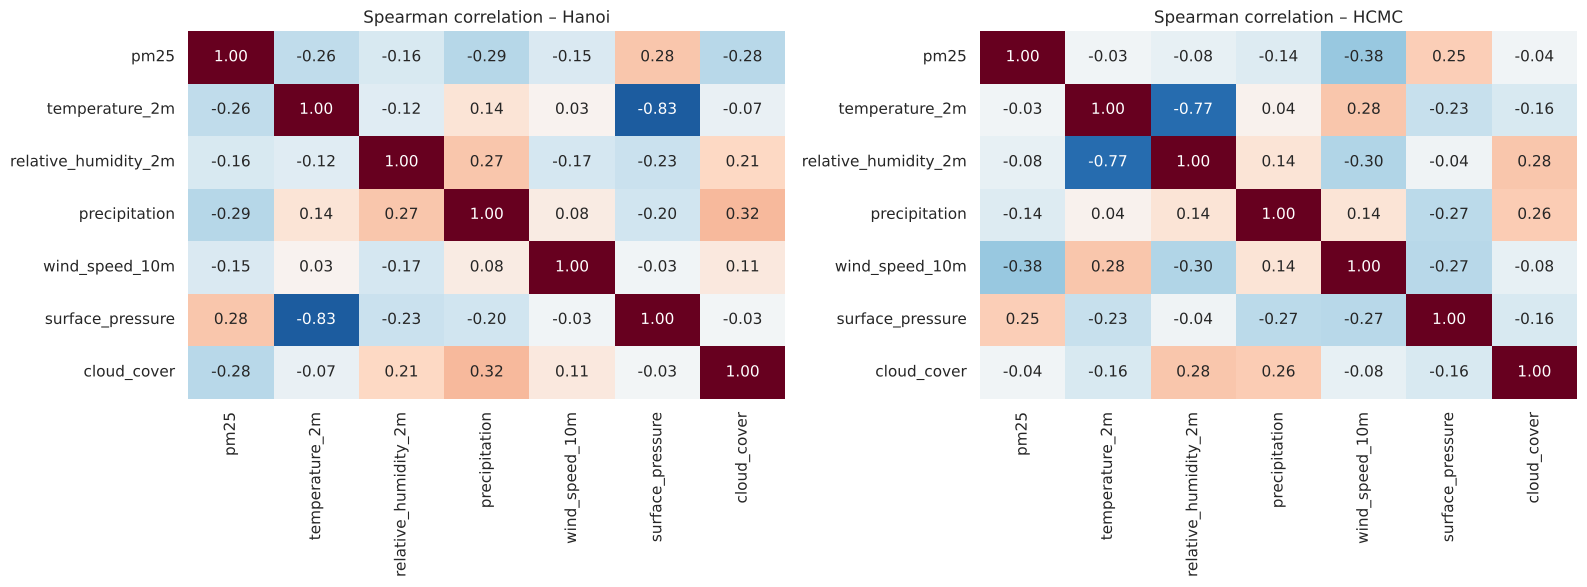

In [7]:
num_cols = ['pm25', 'temperature_2m', 'relative_humidity_2m', 'precipitation',
            'wind_speed_10m', 'surface_pressure', 'cloud_cover']
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, (city, df) in zip(axes, raw.items()):
    sns.heatmap(df[num_cols].corr(method='spearman'), annot=True, fmt='.2f', cmap='RdBu_r',
                vmin=-1, vmax=1, ax=ax, cbar=False)
    ax.set_title(f'Spearman correlation – {city}')
    print(f'{city} – Spearman correlation of PM2.5 with:',
          df[num_cols].corr(method='spearman')['pm25'].drop('pm25').round(2).to_dict())
plt.tight_layout()
plt.show()

**Autocorrelation.** How much does the current value tell us about the value $k$ hours later? The lag-$k$ autocorrelation is the
Pearson correlation between the pairs $(x_t, x_{t-k})$ for all $t$ where both hours were measured
(`Series.autocorr(k)` in pandas). Lag 24h is the relevant one for a 24-hour-ahead forecast.

In [8]:
ACF_LAGS = [1, 2, 3, 6, 12, 24, 48]
acf_table = pd.DataFrame({city: [df['pm25'].autocorr(lag) for lag in ACF_LAGS] for city, df in raw.items()},
                         index=pd.Index(ACF_LAGS, name='lag (hours)'))
display(acf_table.round(2))

,Hanoi,HCMC
lag (hours),,
1,0.92,0.88
2,0.86,0.75
3,0.81,0.64
6,0.73,0.41
12,0.62,0.27
24,0.56,0.45
48,0.43,0.35


**EDA findings:**


(Every number below is printed by a cell above: the statistics table in 1.3, the monthly table under Figure 3, the printout under Figure 4,
the Spearman printout under Figure 5 and the autocorrelation table.)
- **Similar average pollution, different shapes:** mean hourly PM2.5 is 31.7 µg/m³ in Hanoi and 32.1 µg/m³ in HCMC.
  Hanoi is more volatile (std 20.6 vs 16.3; max 332 vs 171 µg/m³).
- **WHO guideline (24-hour mean ≤ 15 µg/m³):** it is exceeded on **91.3% of the 389 valid days in Hanoi** and **98.2% of the 613 valid days in HCMC**
  (valid day = at least 18 measured hours). Both cities are almost always above the guideline.
- **Seasonality (monthly means):** Hanoi has a clear winter pollution season (December 53.3, January 55.0 µg/m³) and is cleanest in August (19.4),
  almost a 3× difference. HCMC is also most polluted at the turn of the year (January 46.2) and cleanest in July (23.5), with a narrower range.
  Figure 3 shows medians, which are a few µg/m³ lower (e.g. Hanoi January: median 52.8) because the distribution is right-skewed.
- **Daily cycle (complete days only):** HCMC peaks in the morning rush hour in both half-years (7h: 45.7 µg/m³ in Nov–Apr, 35.6 in May–Oct).
  Hanoi in Nov–Apr peaks around midnight (0h: 43.4) and is lowest at 17h (38.7), consistent with a shallow night-time boundary layer
  trapping dust near the ground and daytime mixing diluting it; its daily cycle is weak compared with its seasonal cycle.
  Without the complete-day filter the Hanoi curve shows a spurious noon peak, an artefact of the missing afternoons after 11/2025.
- **Correlation with weather (Spearman):** in Hanoi PM2.5 is lower with rain (−0.29), cloud cover (−0.28) and higher temperature (−0.26), and higher with
  surface pressure (+0.28): cold, dry, high-pressure winter air lets dust accumulate. In HCMC the strongest link is wind speed (−0.38): wind disperses dust.
  These are monotonic associations, not causal effects (season drives several of them at once).
- **Autocorrelation:** 0.92 (Hanoi) / 0.88 (HCMC) at lag 1h, but only 0.56 / 0.45 at lag 24h. Forecasting 24h ahead is therefore much harder
  than forecasting the next hour and needs weather, season and daily-cycle features. (In HCMC the autocorrelation at 24h is higher than at 12h, 0.45 vs 0.27:
  the same hour of the day tends to repeat.)
- **Data quality:** Hanoi is missing 32.8% of PM2.5 hours. Until October 2025 at most 12% of each month is missing, but **from November 2025 onwards
  31–97% of every month is missing** (December 2025: 97%), and the station rarely reports in the afternoon. HCMC is missing 8.4%.
  The Validation and Test periods of Hanoi fall entirely in this degraded period, which must be kept in mind when reading the results.

## 2. DATA PREPARATION

The steps below are written as **reusable functions** and applied **identically** to each city,
but every city is processed **independently**.

### 2.1. Missing value statistics

,City,Missing hours,Missing rate,Gaps,Gaps ≤ 6h,Longest gap (hours)
0,Hanoi,5269,32.8%,212,89,859
1,HCMC,1345,8.4%,65,52,690


,Hanoi (% missing),HCMC (% missing)
city,0.00,0.00
temperature_2m,0.00,0.00
relative_humidity_2m,0.00,0.00
precipitation,0.00,0.00
wind_speed_10m,0.00,0.00
wind_direction_10m,0.00,0.00
surface_pressure,0.00,0.00
cloud_cover,0.00,0.00
pm25,32.82,8.38
pm25_source,0.00,0.00


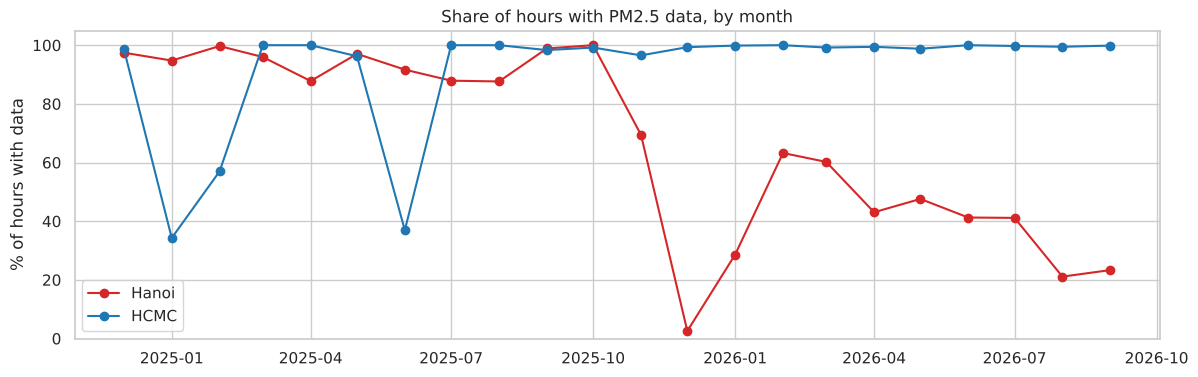

% of hours with missing PM2.5, by month:


datetime,2024-12,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,...,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09
Hanoi,3,5,0,4,12,3,8,12,12,1,...,97,71,37,40,57,52,59,59,79,77
HCMC,1,66,43,0,0,4,63,0,0,2,...,1,0,0,1,1,1,0,0,1,0


In [9]:
def gap_lengths(series):
    """Length (hours) of each run of consecutive missing values."""
    is_na = series.isna()
    groups = (is_na != is_na.shift()).cumsum()
    return is_na.groupby(groups).sum()[lambda s: s > 0]


def missing_report(raw_dict):
    rows = []
    for city, df in raw_dict.items():
        gaps = gap_lengths(df['pm25'])
        rows.append({'City': city, 'Missing hours': int(df['pm25'].isna().sum()),
                     'Missing rate': f"{df['pm25'].isna().mean():.1%}",
                     'Gaps': len(gaps), 'Gaps ≤ 6h': int((gaps <= 6).sum()),
                     'Longest gap (hours)': int(gaps.max()) if len(gaps) else 0})
    return pd.DataFrame(rows)


display(missing_report(raw))
display((pd.concat({city: df.isna().mean() for city, df in raw.items()}, axis=1) * 100)
        .round(2).rename(columns=lambda c: f'{c} (% missing)'))

fig, ax = plt.subplots(figsize=(14, 4))
for city, df in raw.items():
    avail = df['pm25'].notna().resample('MS').mean() * 100
    ax.plot(avail.index, avail, marker='o', label=city, color=CITY_COLORS[city])
ax.set(title='Share of hours with PM2.5 data, by month', ylabel='% of hours with data', ylim=(0, 105))
ax.legend()
plt.show()

missing_by_month = pd.DataFrame({city: df['pm25'].isna().resample('MS').mean() * 100 for city, df in raw.items()})
missing_by_month.index = missing_by_month.index.strftime('%Y-%m')
print('% of hours with missing PM2.5, by month:')
display(missing_by_month.round(0).astype(int).T)

### 2.2. Cleaning invalid values and handling missing data

- **Invalid values:** PM2.5 ≤ 0 or > 1000 µg/m³ are sensor errors → set to `NaN`
  (a reference monitor reporting exactly 0.0 is a dropout, not clean air).
- **"Stuck" sensor:** the same value repeated for ≥ 6 consecutive hours (with PM2.5 > 0) indicates a frozen device → set to `NaN`.
- **No look-ahead when filling.** Time interpolation (`interpolate(method='time')`) fills a gap using the value measured **after**
  the gap, which is not known yet at forecast time $t$. If the features were built from interpolated values, the model would
  see up to 6 hours of the future (Section 2.4 prints how many samples this would concern). We therefore keep two versions:
  - `pm25_raw` — the measured values only. **The target is always a measured value** (never filled), so the evaluation is done on real data.
  - `pm25` — `pm25_raw` **forward-filled for at most 6 hours** (`ffill(limit=6)`): "the last known value, if it is at most 6h old".
    This is causal (uses only data ≤ $t$) and is used to build the features.
- **Long gaps (> 6 hours):** not filled (that would fabricate data) → samples whose current value or target is missing are dropped;
  remaining missing features are handled by `SimpleImputer` (median, fitted on the training set) inside the pipeline.

Hanoi: 4 values ≤ 0 or > 1000, 0 stuck-sensor hours | missing PM2.5: 32.8% → 26.0% after cleaning + causal forward-fill (features only)
HCMC: 0 values ≤ 0 or > 1000, 0 stuck-sensor hours | missing PM2.5: 8.4% → 7.3% after cleaning + causal forward-fill (features only)


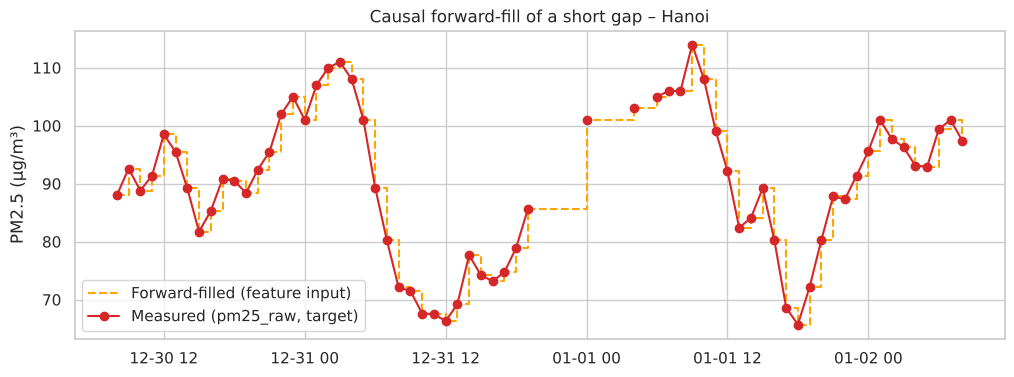

In [10]:
MAX_FILL_GAP = 6
STUCK_HOURS = 6


def clean_city(df):
    df = df.copy()
    pm = df['pm25']
    invalid = (pm <= 0) | (pm > 1000)
    run_id = (pm != pm.shift()).cumsum()
    run_len = pm.groupby(run_id).transform('size')
    stuck = (run_len >= STUCK_HOURS) & (pm > 0) & pm.notna()
    df.loc[invalid | stuck, 'pm25'] = np.nan
    df['pm25_raw'] = df['pm25']                                # measured values only (used for the target)
    df['pm25'] = df['pm25_raw'].ffill(limit=MAX_FILL_GAP)      # causal fill (used for the features)
    return df, int(invalid.sum()), int(stuck.sum())


clean = {}
for city, df in raw.items():
    clean[city], n_invalid, n_stuck = clean_city(df)
    before, after = df['pm25'].isna().mean(), clean[city]['pm25'].isna().mean()
    print(f'{city}: {n_invalid} values ≤ 0 or > 1000, {n_stuck} stuck-sensor hours | '
          f'missing PM2.5: {before:.1%} → {after:.1%} after cleaning + causal forward-fill (features only)')


def first_short_gap(series, min_len=3, max_len=MAX_FILL_GAP):
    is_na = series.isna()
    groups = (is_na != is_na.shift()).cumsum()
    sizes = is_na.groupby(groups).transform('sum')
    mask = is_na & (sizes >= min_len) & (sizes <= max_len)
    return series.index[mask][0] if mask.any() else None


for city in clean:
    gap_time = first_short_gap(clean[city]['pm25_raw'])
    if gap_time is not None:
        break
if gap_time is not None:
    window = clean[city].loc[gap_time - pd.Timedelta('36h'): gap_time + pd.Timedelta('36h')]
    fig, ax = plt.subplots(figsize=(12, 4))
    ax.step(window.index, window['pm25'], where='post', ls='--', color='orange', label='Forward-filled (feature input)')
    ax.plot(window.index, window['pm25_raw'], 'o-', color=CITY_COLORS[city], label='Measured (pm25_raw, target)')
    ax.set(title=f'Causal forward-fill of a short gap – {city}', ylabel='PM2.5 (µg/m³)')
    ax.legend()
    plt.show()

### 2.3. Outlier detection (IQR)
IQR rule: values outside $[Q1 - 3\cdot IQR,\ Q3 + 3\cdot IQR]$ are treated as extreme outliers.

Hanoi: upper bound = 103.2 µg/m³ | 93 outlier hours (0.86%) | days with most outliers: ['2026-02-06', '2024-12-22', '2025-02-20']
HCMC: upper bound = 94.9 µg/m³ | 111 outlier hours (0.75%) | days with most outliers: ['2026-01-11', '2025-11-16', '2025-12-13']


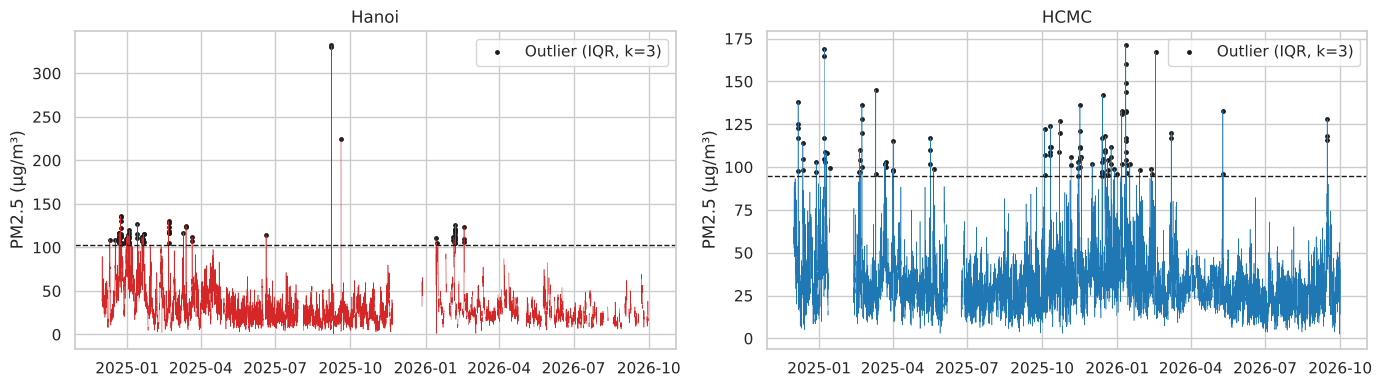

In [11]:
def iqr_bounds(s, k=3.0):
    q1, q3 = s.quantile([0.25, 0.75])
    return q1 - k * (q3 - q1), q3 + k * (q3 - q1)


fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, (city, df) in zip(axes, clean.items()):
    lo, hi = iqr_bounds(df['pm25_raw'])
    out = df.loc[df['pm25_raw'] > hi, 'pm25_raw']
    top_days = out.resample('D').count().nlargest(3).index.strftime('%Y-%m-%d').tolist()
    print(f'{city}: upper bound = {hi:.1f} µg/m³ | {len(out)} outlier hours '
          f'({len(out) / df.pm25_raw.notna().sum():.2%}) | days with most outliers: {top_days}')
    ax.plot(df.index, df['pm25_raw'], lw=0.4, color=CITY_COLORS[city])
    ax.scatter(out.index, out, s=6, color='k', label='Outlier (IQR, k=3)')
    ax.axhline(hi, color='k', ls='--', lw=1)
    ax.set(title=city, ylabel='PM2.5 (µg/m³)')
    ax.legend()
plt.tight_layout()
plt.show()

**Outlier decision:** PM2.5 peaks are **real events** (winter pollution episodes, straw burning, fireworks...),
so they are **not removed** from the target (removing them would make the evaluation look better than it is). Instead, the PM2.5
**features** (lags, rolling statistics) go through a custom `IQRClipper` transformer (bounds learned **on the training set only**)
to reduce the influence of extreme values on the linear model.

### 2.4. Feature engineering

Each sample at time $t$ has target `y = pm25_raw(t + 24h)` (a **measured** value). The features are built from the forward-filled
series and use only information **available at $t$** (no future leakage):

| Group | Features | Type |
|---|---|---|
| PM2.5 history | `pm25_lag_0, 1, 2, 3, 6, 12, 23` (value at $t-k$), `pm25_roll_mean_6/24`, `pm25_roll_std_24`, `pm25_diff_24` | numerical |
| Weather at $t$ | temperature, humidity, precipitation, wind speed, pressure, cloud cover, `rain_24h` (total rain over the last 24h) | numerical |
| Calendar of the forecast time | `hour_sin/cos` (cyclic hour encoding) | numerical |
| | `season` (climate season of each city), `day_of_week`, `wind_sector` (8 wind directions) | **categorical** |

> `pm25_lag_0` is the value at the **same hour on the previous day** relative to the forecast time, so the
> **Persistence** baseline (`ŷ(t+24) = pm25(t)`) is also the 24h *seasonal naive* baseline.

In [12]:
SEASONS = {
    'Hanoi': {12: 'Winter', 1: 'Winter', 2: 'Winter', 3: 'Spring', 4: 'Spring', 5: 'Spring',
              6: 'Summer', 7: 'Summer', 8: 'Summer', 9: 'Autumn', 10: 'Autumn', 11: 'Autumn'},
    'HCMC': {m: ('Dry season' if m in (12, 1, 2, 3, 4) else 'Wet season') for m in range(1, 13)},
}
WIND_SECTORS = ['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW']
LAGS = [0, 1, 2, 3, 6, 12, 23]
WEATHER_RAW = ['temperature_2m', 'relative_humidity_2m', 'precipitation', 'wind_speed_10m',
               'surface_pressure', 'cloud_cover']
WEATHER_FEATURES = WEATHER_RAW + ['rain_24h']
PM_FEATURES = [f'pm25_lag_{k}' for k in LAGS] + ['pm25_roll_mean_6', 'pm25_roll_mean_24',
                                                 'pm25_roll_std_24', 'pm25_diff_24']
CYCLIC_FEATURES = ['hour_sin', 'hour_cos']
CAT_FEATURES = ['season', 'day_of_week', 'wind_sector']
FEATURES = PM_FEATURES + WEATHER_FEATURES + CYCLIC_FEATURES + CAT_FEATURES
TARGET = 'target'


def build_features(df, city, horizon=HORIZON):
    """Build the features at each time t (using only data ≤ t)."""
    pm = df['pm25']
    X = pd.DataFrame(index=df.index)
    for k in LAGS:
        X[f'pm25_lag_{k}'] = pm.shift(k)
    X['pm25_roll_mean_6'] = pm.rolling(6, min_periods=3).mean()
    X['pm25_roll_mean_24'] = pm.rolling(24, min_periods=12).mean()
    X['pm25_roll_std_24'] = pm.rolling(24, min_periods=12).std()
    X['pm25_diff_24'] = pm - pm.shift(24)
    X[WEATHER_RAW] = df[WEATHER_RAW]
    X['rain_24h'] = df['precipitation'].rolling(24, min_periods=1).sum()

    target_time = df.index + pd.Timedelta(hours=horizon)
    X['hour_sin'] = np.sin(2 * np.pi * target_time.hour / 24)
    X['hour_cos'] = np.cos(2 * np.pi * target_time.hour / 24)
    X['season'] = pd.Series(target_time.month, index=df.index).map(SEASONS[city])
    X['day_of_week'] = target_time.day_name()
    sector_idx = ((df['wind_direction_10m'] + 22.5) % 360) // 45
    X['wind_sector'] = sector_idx.map(lambda i: WIND_SECTORS[int(i)] if pd.notna(i) else np.nan)
    return X


def make_dataset(df, city, horizon=HORIZON):
    """Add target = measured pm25_raw(t + horizon); keep only samples with a target and a current value."""
    X = build_features(df, city, horizon)
    X[TARGET] = df['pm25_raw'].shift(-horizon)
    return X.dropna(subset=[TARGET, 'pm25_lag_0'])


datasets = {city: make_dataset(df, city) for city, df in clean.items()}
for city, d in datasets.items():
    filled_now = clean[city]['pm25_raw'].reindex(d.index).isna().mean()   # current value comes from the forward-fill
    print(f'{city}: {len(d):,} samples | {len(FEATURES)} features '
          f'({len(FEATURES) - len(CAT_FEATURES)} numerical + {len(CAT_FEATURES)} categorical) | '
          f'{filled_now:.1%} of samples have a forward-filled current value '
          f'(with two-sided interpolation these would have used future measurements)')
datasets['Hanoi'].head()

Hanoi: 9,869 samples | 23 features (20 numerical + 3 categorical) | 2.8% of samples have a forward-filled current value (with two-sided interpolation these would have used future measurements)
HCMC: 14,566 samples | 23 features (20 numerical + 3 categorical) | 0.9% of samples have a forward-filled current value (with two-sided interpolation these would have used future measurements)


,pm25_lag_0,pm25_lag_1,pm25_lag_2,pm25_lag_3,pm25_lag_6,pm25_lag_12,pm25_lag_23,pm25_roll_mean_6,pm25_roll_mean_24,pm25_roll_std_24,...,wind_speed_10m,surface_pressure,cloud_cover,rain_24h,hour_sin,hour_cos,season,day_of_week,wind_sector,target
datetime,,,,,,,,,,,,,,,,,,,,,
2024-12-01 00:00:00,39.5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,3.3,1012.9,94,0.0,0.000000,1.000000,Winter,Monday,S,41.5
2024-12-01 01:00:00,41.6,39.5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2.6,1012.7,97,0.0,0.258819,0.965926,Winter,Monday,S,37.3
2024-12-01 02:00:00,38.8,41.6,39.5,NaN,NaN,NaN,NaN,39.966667,NaN,NaN,...,0.8,1012.0,94,0.0,0.500000,0.866025,Winter,Monday,SE,44.2
2024-12-01 03:00:00,43.0,38.8,41.6,39.5,NaN,NaN,NaN,40.725000,NaN,NaN,...,1.8,1011.7,93,0.0,0.707107,0.707107,Winter,Monday,NE,40.2
2024-12-01 04:00:00,41.9,43.0,38.8,41.6,NaN,NaN,NaN,40.960000,NaN,NaN,...,3.3,1011.4,86,0.0,0.866025,0.500000,Winter,Monday,NE,40.7


### 2.5. Chronological Train / Validation / Test split
A time series **must not be shuffled** (that would leak the future into the past). The split follows **time order**:
first 70% → Train, next 15% → Validation (model selection), last 15% → Test (final evaluation).
An extra `HORIZON` = 24 hours is dropped before each boundary so that the **targets** of one set do not fall inside the next set's period.

Hanoi split: Train 6,884 | Validation 1,462 | Test 1,481 samples | mean target: Train 33.5, Validation 30.1, Test 25.5 µg/m³
HCMC split: Train 10,177 | Validation 2,161 | Test 2,185 samples | mean target: Train 34.5, Validation 26.9, Test 25.9 µg/m³


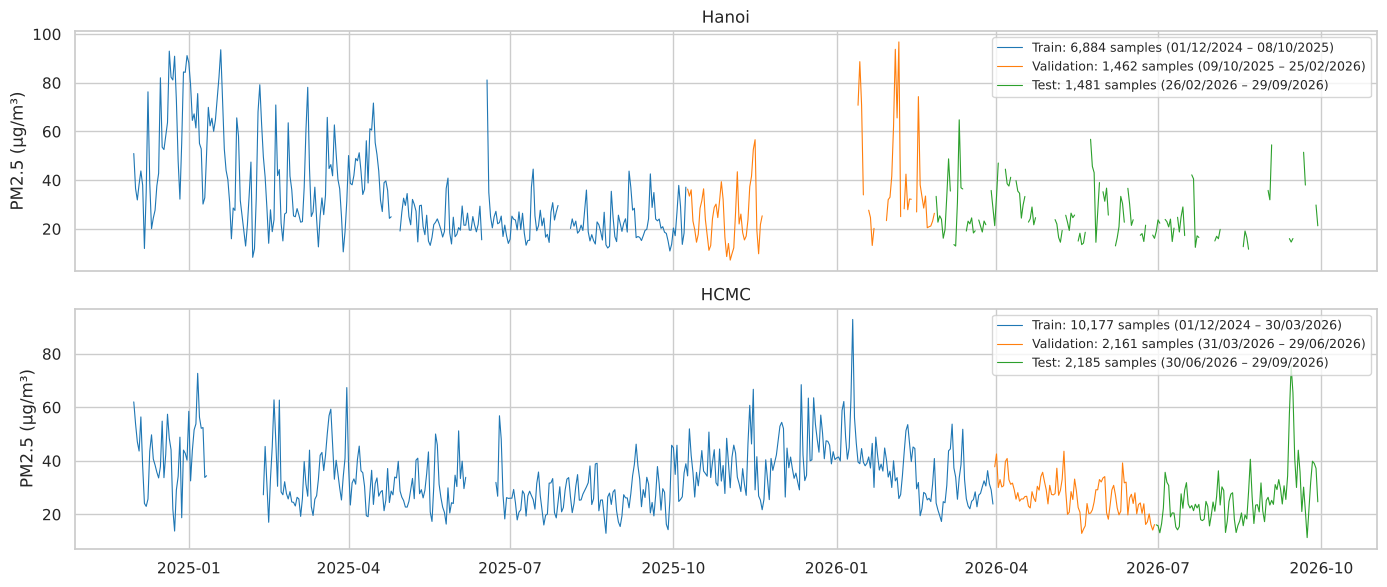

In [13]:
def time_split(d, train_frac=0.70, val_frac=0.15, gap_hours=HORIZON):
    n = len(d)
    t1, t2 = d.index[int(n * train_frac)], d.index[int(n * (train_frac + val_frac))]
    gap = pd.Timedelta(hours=gap_hours)
    train = d[d.index < t1 - gap]
    val = d[(d.index >= t1) & (d.index < t2 - gap)]
    test = d[d.index >= t2]
    return train, val, test


splits = {city: time_split(d) for city, d in datasets.items()}

fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
for ax, (city, (tr, va, te)) in zip(axes, splits.items()):
    for part, name, color in [(tr, 'Train', 'tab:blue'), (va, 'Validation', 'tab:orange'), (te, 'Test', 'tab:green')]:
        daily = part[TARGET].resample('D').mean()
        ax.plot(daily.index, daily, color=color, lw=0.8,
                label=f'{name}: {len(part):,} samples ({part.index.min():%d/%m/%Y} – {part.index.max():%d/%m/%Y})')
    ax.set(title=city, ylabel='PM2.5 (µg/m³)')
    ax.legend(loc='upper right', fontsize=9)
    print(f'{city} split: Train {len(tr):,} | Validation {len(va):,} | Test {len(te):,} samples | '
          f'mean target: Train {tr[TARGET].mean():.1f}, Validation {va[TARGET].mean():.1f}, Test {te[TARGET].mean():.1f} µg/m³')
plt.tight_layout()
plt.show()

**Figure caption (split):** Train / Validation / Test have 6,884 / 1,462 / 1,481 samples in Hanoi and 10,177 / 2,161 / 2,185 in HCMC.
The mean target drops from Train to Test (Hanoi 33.5 → 30.1 → 25.5 µg/m³, HCMC 34.5 → 26.9 → 25.9 µg/m³): the later sets fall in the
cleaner season, so the models are evaluated on a distribution they saw less of. Because Hanoi has more missing data, its Validation and Test
periods start earlier (Test 26/02/2026, vs 30/06/2026 for HCMC) — another reason to compare relative gains, not absolute MAE, between cities.

### 2.6. Preprocessing pipeline (imputation, outlier clipping, encoding, scaling)

| Column group | Steps |
|---|---|
| PM2.5 lags/rolling | `SimpleImputer(median)` → `IQRClipper(k=3)` → `StandardScaler` |
| Weather + hour cycle | `SimpleImputer(median)` → `StandardScaler` |
| Categorical | `SimpleImputer(most_frequent)` → `OneHotEncoder` |

Everything lives inside a `ColumnTransformer` + `Pipeline`, so all parameters (medians, IQR bounds, mean/std, categories)
are **learned on the training set only** → no data leakage.

After preprocessing: 39 columns (from 23 original columns, one-hot expands the categoricals)
Missing values left after the pipeline: 0


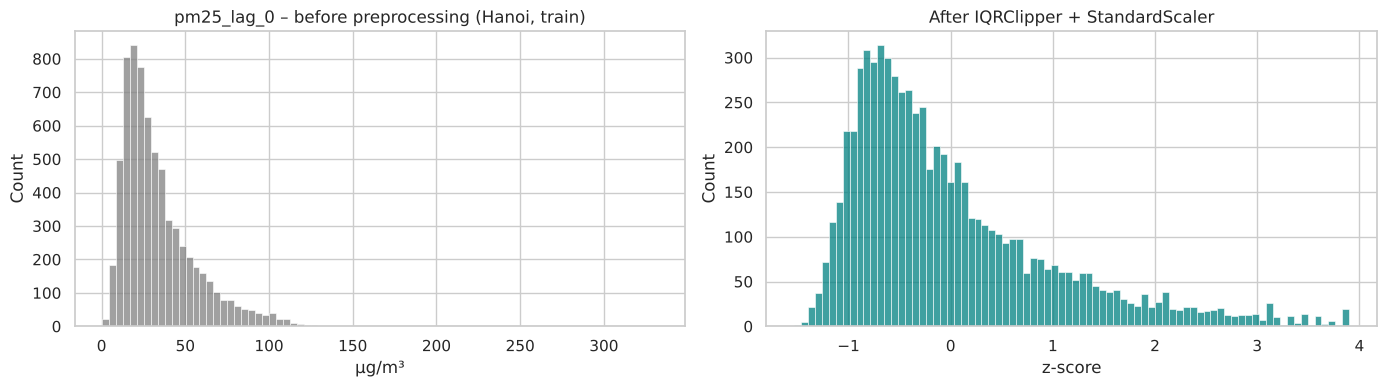

In [14]:
class IQRClipper(BaseEstimator, TransformerMixin):
    """Clip (winsorize) each column to [Q1 - k·IQR, Q3 + k·IQR], bounds learned on the fitted data."""

    def __init__(self, k=3.0):
        self.k = k

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        q1, q3 = np.nanpercentile(X, [25, 75], axis=0)
        self.lower_, self.upper_ = q1 - self.k * (q3 - q1), q3 + self.k * (q3 - q1)
        return self

    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.lower_, self.upper_)

    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features, dtype=object)


def build_preprocessor():
    return ColumnTransformer([
        ('pm', Pipeline([('impute', SimpleImputer(strategy='median')),
                         ('clip', IQRClipper(k=3.0)),
                         ('scale', StandardScaler())]), PM_FEATURES),
        ('num', Pipeline([('impute', SimpleImputer(strategy='median')),
                          ('scale', StandardScaler())]), WEATHER_FEATURES + CYCLIC_FEATURES),
        ('cat', Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
                          ('onehot', OneHotEncoder(handle_unknown='ignore'))]), CAT_FEATURES),
    ], sparse_threshold=0)


tr = splits['Hanoi'][0]
pre = build_preprocessor().fit(tr[FEATURES])
Xt = pd.DataFrame(pre.transform(tr[FEATURES]), columns=pre.get_feature_names_out(), index=tr.index)
print(f'After preprocessing: {Xt.shape[1]} columns (from {len(FEATURES)} original columns, one-hot expands the categoricals)')
print('Missing values left after the pipeline:', int(Xt.isna().sum().sum()))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(tr['pm25_lag_0'], bins=80, ax=axes[0], color='gray')
axes[0].set(title='pm25_lag_0 – before preprocessing (Hanoi, train)', xlabel='µg/m³')
sns.histplot(Xt['pm__pm25_lag_0'], bins=80, ax=axes[1], color='teal')
axes[1].set(title='After IQRClipper + StandardScaler', xlabel='z-score')
plt.tight_layout()
plt.show()

## 3. ANALYSIS AND MODELING

### 3.1. Models compared
| Model | Role | Why |
|---|---|---|
| **Persistence (baseline)** | `ŷ(t+24) = pm25(t)` | Standard time series baseline (= 24h seasonal naive) |
| **Mean 24h (baseline)** | `ŷ(t+24) = mean(pm25[t-23 … t])` | Smooths out the noise of a single hour |
| **Naive blend (baseline)** | `ŷ = w·pm25(t) + (1−w)·mean_24h(t)` | The **strongest naive baseline**: `w` is learned on the training data (grid 0, 0.05, …, 1, minimizing MAE). An ML model is only really useful if it beats **this** one, not just Persistence |
| **Ridge Regression** | Regularized linear model | Simple and interpretable; tests how linear the relationship is |
| **Random Forest** | Tree ensemble (bagging) | Captures non-linear effects and weather × hour interactions |
| **HistGradientBoosting** | Tree ensemble (boosting) | Strong and fast on large tabular data |

**Hyperparameter tuning:** `GridSearchCV` with `TimeSeriesSplit(n_splits=3, gap=24)` on the training set, scored by `MAE`.
The validation fold always comes **after** the training fold, and the `gap` drops 24 samples between them so that the targets
(24h ahead) of the last training samples do not fall inside the validation fold. All three ML models are tuned
(Random Forest with a small grid to keep the run time reasonable on Colab).

The `CityForecaster` class wraps the whole workflow for **one** city so that it can be repeated for both.

In [15]:
class PersistenceBaseline(BaseEstimator, RegressorMixin):
    """Forecast PM2.5 HORIZON hours ahead with the current value."""

    def fit(self, X, y=None):
        return self

    def predict(self, X):
        return np.asarray(X['pm25_lag_0'], dtype=float)


class MeanBaseline(BaseEstimator, RegressorMixin):
    """Forecast PM2.5 HORIZON hours ahead with the mean of the last 24 hours."""

    def fit(self, X, y=None):
        return self

    def predict(self, X):
        return np.asarray(X['pm25_roll_mean_24'].fillna(X['pm25_lag_0']), dtype=float)


class NaiveBlend(BaseEstimator, RegressorMixin):
    """w·(current value) + (1 − w)·(24h mean); w is chosen on the fitted data to minimize MAE."""

    def __init__(self, weights=tuple(np.round(np.linspace(0, 1, 21), 2))):
        self.weights = weights

    @staticmethod
    def _parts(X):
        now = np.asarray(X['pm25_lag_0'], dtype=float)
        return now, np.asarray(X['pm25_roll_mean_24'].fillna(X['pm25_lag_0']), dtype=float)

    def fit(self, X, y):
        now, mean24 = self._parts(X)
        maes = [np.mean(np.abs(np.asarray(y) - (w * now + (1 - w) * mean24))) for w in self.weights]
        self.w_ = float(self.weights[int(np.argmin(maes))])
        return self

    def predict(self, X):
        now, mean24 = self._parts(X)
        return self.w_ * now + (1 - self.w_) * mean24


BASELINES = ['Persistence (baseline)', 'Mean 24h (baseline)', 'Naive blend (baseline)']


def regression_metrics(y_true, y_pred):
    return {'MAE': mean_absolute_error(y_true, y_pred),
            'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
            'R2': r2_score(y_true, y_pred)}


def make_models():
    return {
        'Persistence (baseline)': PersistenceBaseline(),
        'Mean 24h (baseline)': MeanBaseline(),
        'Naive blend (baseline)': NaiveBlend(),
        'Ridge': Pipeline([('pre', build_preprocessor()), ('model', Ridge())]),
        'RandomForest': Pipeline([('pre', build_preprocessor()), ('model', RandomForestRegressor(
            n_estimators=200, max_depth=12, min_samples_leaf=10, max_features=0.5,
            n_jobs=-1, random_state=RANDOM_STATE))]),
        'HistGradientBoosting': Pipeline([('pre', build_preprocessor()),
                                          ('model', HistGradientBoostingRegressor(random_state=RANDOM_STATE))]),
    }


PARAM_GRIDS = {
    'Ridge': {'model__alpha': [0.1, 1, 10, 100]},
    'RandomForest': {'model__max_depth': [8, 12],
                     'model__min_samples_leaf': [10, 30]},
    'HistGradientBoosting': {'model__learning_rate': [0.03, 0.1],
                             'model__max_iter': [200, 400],
                             'model__max_leaf_nodes': [15, 31],
                             'model__l2_regularization': [0.0, 1.0]},
}


class CityForecaster:
    def __init__(self, city, train, val, test):
        self.city, self.train, self.val, self.test = city, train, val, test
        self.models = make_models()
        self.best_params = {}

    def tune(self):
        for name, grid in PARAM_GRIDS.items():
            search = GridSearchCV(self.models[name], grid, cv=TimeSeriesSplit(n_splits=3, gap=HORIZON),
                                  scoring='neg_mean_absolute_error', n_jobs=-1)
            search.fit(self.train[FEATURES], self.train[TARGET])
            self.models[name] = search.best_estimator_
            self.best_params[name] = search.best_params_
        return self

    def evaluate_on_validation(self):
        rows, self.val_predictions = [], pd.DataFrame({'actual': self.val[TARGET]})
        for name, m in self.models.items():
            m.fit(self.train[FEATURES], self.train[TARGET])
            pred = m.predict(self.val[FEATURES])
            self.val_predictions[name] = pred
            rows.append({'city': self.city, 'model': name, **regression_metrics(self.val[TARGET], pred)})
        return pd.DataFrame(rows)

    def evaluate_on_test(self):
        """Retrain on Train + Validation, then evaluate once on Test."""
        full = pd.concat([self.train, self.val])
        rows, self.test_predictions = [], pd.DataFrame({'actual': self.test[TARGET]})
        for name, m in self.models.items():
            m.fit(full[FEATURES], full[TARGET])
            pred = m.predict(self.test[FEATURES])
            self.test_predictions[name] = pred
            rows.append({'city': self.city, 'model': name, **regression_metrics(self.test[TARGET], pred)})
        return pd.DataFrame(rows)


forecasters = {city: CityForecaster(city, *parts).tune() for city, parts in splits.items()}
for city, f in forecasters.items():
    print(f'{city} – best hyperparameters:')
    for name, params in f.best_params.items():
        print(f'   {name}: {params}')
    blend = f.models['Naive blend (baseline)'].fit(f.train[FEATURES], f.train[TARGET])
    print(f'   Naive blend: w = {blend.w_:.2f} (weight of the current value, learned on Train)')

Hanoi – best hyperparameters:
   Ridge: {'model__alpha': 100}
   RandomForest: {'model__max_depth': 8, 'model__min_samples_leaf': 30}
   HistGradientBoosting: {'model__l2_regularization': 0.0, 'model__learning_rate': 0.03, 'model__max_iter': 200, 'model__max_leaf_nodes': 31}
   Naive blend: w = 0.45 (weight of the current value, learned on Train)
HCMC – best hyperparameters:
   Ridge: {'model__alpha': 100}
   RandomForest: {'model__max_depth': 12, 'model__min_samples_leaf': 30}
   HistGradientBoosting: {'model__l2_regularization': 1.0, 'model__learning_rate': 0.03, 'model__max_iter': 200, 'model__max_leaf_nodes': 15}
   Naive blend: w = 0.50 (weight of the current value, learned on Train)


### 3.2. Comparison on the Validation set

In [16]:
val_results = pd.concat([f.evaluate_on_validation() for f in forecasters.values()], ignore_index=True)
val_table = val_results.pivot(index='model', columns='city', values=['MAE', 'RMSE', 'R2'])
display(val_table.reindex(columns=list(CITY_FILES), level=1).reindex(list(make_models())).round(3))

MAE           RMSE             R2       
city                     Hanoi   HCMC   Hanoi    HCMC  Hanoi   HCMC
model                                                              
Persistence (baseline)  13.478  7.656  20.231  10.620  0.006 -0.129
Mean 24h (baseline)     13.754  7.723  19.333   9.969  0.092  0.005
Naive blend (baseline)  13.013  7.062  18.870   9.449  0.135  0.106
Ridge                   12.104  7.025  16.659   9.192  0.326  0.154
RandomForest            12.002  7.500  16.524   9.565  0.337  0.084
HistGradientBoosting    12.473  7.460  17.620   9.531  0.246  0.091

**Validation findings** (Section 3.2):
- Copying the current value (Persistence) is a weak forecast: R² ≈ 0.01 (Hanoi) and −0.13 (HCMC). The **Naive blend**
  (≈ half current value, half 24h mean; `w` = 0.45 / 0.50 learned on Train) is clearly better: MAE 13.01 vs 13.48 (Hanoi) and 7.06 vs 7.66 (HCMC).
  This is the bar a machine learning model has to clear.
- **Hanoi:** all three ML models beat the Naive blend; RandomForest is best (MAE 12.00, ≈ 8% lower than the blend), but Ridge is very close (12.10).
- **HCMC:** only Ridge beats the Naive blend, and only marginally (7.03 vs 7.06, ≈ 0.5%). The tree models (7.46–7.50) are **worse than the naive blend**:
  with a weak signal (R² ≤ 0.15), the strongly regularized linear model (alpha = 100) overfits less.
- GridSearch (with a 24h `gap` between CV folds) picks a small learning rate (0.03) for HGB and large leaves (`min_samples_leaf` = 30) for RandomForest,
  i.e. it prefers simpler models — consistent with noisy data covering only 22 months.
- The differences between the best ML models are small (Hanoi: RF 12.00 vs Ridge 12.10) and are measured on 1,462 (Hanoi) / 2,161 (HCMC) samples.
  Section 4.3 checks with block-bootstrap confidence intervals which of these differences are larger than chance.

## 4. SUMMARY AND EXTENSIONS

### 4.1. Results on the independent Test set
Each model is retrained on Train + Validation (with its hyperparameters fixed) and evaluated **once** on Test.
The **best model of each city is chosen on the Validation set** (lowest Validation MAE, Section 3.2), not on Test,
so the Test set is used only for reporting and the error analysis below is not biased by model selection.

In [17]:
test_results = pd.concat([f.evaluate_on_test() for f in forecasters.values()], ignore_index=True)
for ref, col in [('Persistence (baseline)', 'MAE vs Persistence'), ('Naive blend (baseline)', 'MAE vs Naive blend')]:
    ref_mae = test_results[test_results.model == ref].set_index('city')['MAE']
    test_results[col] = test_results.apply(lambda r: 1 - r['MAE'] / ref_mae[r['city']], axis=1)
display(test_results.set_index(['city', 'model']).style.format(
    {'MAE': '{:.2f}', 'RMSE': '{:.2f}', 'R2': '{:.3f}', 'MAE vs Persistence': '{:+.1%}', 'MAE vs Naive blend': '{:+.1%}'}))
print('Test:', {c: f.test.index.min().strftime('%Y-%m-%d') + ' → ' + f.test.index.max().strftime('%Y-%m-%d')
                for c, f in forecasters.items()})
ml_val = val_results[~val_results.model.isin(BASELINES)]
best_model = ml_val.loc[ml_val.groupby('city')['MAE'].idxmin()].set_index('city')['model']
print('Best model (chosen on Validation):', best_model.to_dict())

Test: {'Hanoi': '2026-02-26 → 2026-09-29', 'HCMC': '2026-06-30 → 2026-09-29'}
Best model (chosen on Validation): {'HCMC': 'Ridge', 'Hanoi': 'RandomForest'}


### 4.2. Question: *How much better than the baseline is machine learning in each city?*
**Figure 6 – Test MAE** of each model, per city. Bar labels: % MAE reduction vs. the **Naive blend** baseline
(the strongest naive forecast), so a negative label means "worse than the naive blend".

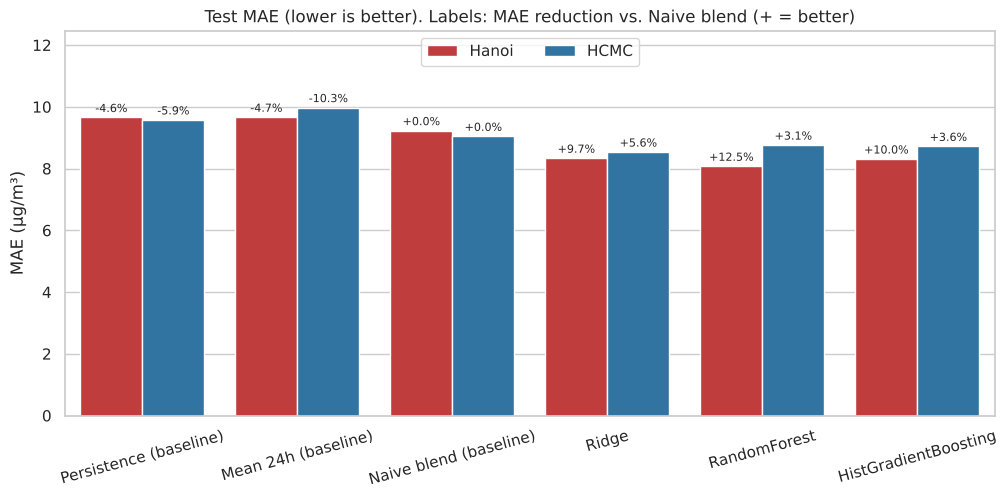

In [18]:
MODEL_ORDER = list(make_models())
fig, ax = plt.subplots(figsize=(12, 5))
sns.barplot(data=test_results, x='model', y='MAE', hue='city', order=MODEL_ORDER,
            hue_order=list(CITY_FILES), palette=CITY_COLORS, ax=ax)
for container, city in zip(ax.containers, CITY_FILES):
    sub = test_results[test_results.city == city].set_index('model')
    ax.bar_label(container, labels=[f"{sub.loc[m, 'MAE vs Naive blend']:+.1%}" for m in MODEL_ORDER],
                 fontsize=8, padding=2)
ax.set(title='Test MAE (lower is better). Labels: MAE reduction vs. Naive blend (+ = better)', xlabel='', ylabel='MAE (µg/m³)')
ax.tick_params(axis='x', labelrotation=15)
ax.set_ylim(0, test_results['MAE'].max() * 1.25)
ax.legend(title='', loc='upper center', ncol=2)
plt.show()

**Figure 6 caption:** On the independent Test set the best model of each city (chosen on Validation) reaches
**MAE 8.08 µg/m³ in Hanoi (RandomForest)** and **8.54 µg/m³ in HCMC (Ridge)**. Against the two reference forecasts:

| City | vs Persistence | vs Naive blend (strongest naive baseline) |
|---|---|---|
| Hanoi (RandomForest) | 9.66 → 8.08 (−16.4%) | 9.23 → 8.08 (**−12.5%**) |
| HCMC (Ridge) | 9.58 → 8.54 (−10.9%) | 9.05 → 8.54 (**−5.6%**) |

Comparing only with Persistence overstates the benefit of machine learning: part of the gain comes from simply smoothing the current value
with its 24h mean. The honest answer to question 1 is therefore **≈ 12% in Hanoi and ≈ 6% in HCMC** beyond the best naive forecast.
In HCMC the tree models are only 3.1–3.6% better than the blend on Test (and worse on Validation), so the linear Ridge model is the only one that adds a consistent gain.
Section 4.3 checks whether these gains are larger than chance: the Hanoi gain over the Naive blend is, the HCMC gain is not.

Note: only **measured** PM2.5 values are used as targets (no interpolated targets), and the features use a causal forward-fill only.
The two Test periods differ (Hanoi 26/02–29/09/2026, HCMC 30/06–29/09/2026, because Hanoi has more missing data), and Hanoi's Test set has
almost no afternoon hours (the station rarely reports 14h–19h after late 2025), so absolute MAE values should not be compared between cities —
compare the relative improvement instead. Hanoi's Test MAE is lower than its Validation MAE (8.1 vs 12.0) because the Test period contains only the end of winter;
HCMC is the opposite (8.5 vs 7.0) because dust rises again in September.
(Tree-model results can shift by a few hundredths of µg/m³ between scikit-learn versions; Ridge and the baselines do not change.)

### 4.3. Are the differences real? Block-bootstrap confidence intervals
A Test set of 1,500–2,200 hours sounds large, but forecast errors are **strongly autocorrelated** (an error at 10h is very
likely to be followed by a similar error at 11h), so the number of *independent* observations is much smaller, and an
ordinary i.i.d. bootstrap over hours would give intervals that are far too narrow.

**Method (non-overlapping block bootstrap, Carlstein 1986; the block idea for dependent data is also in Künsch 1989).**
For a comparison of model $A$ (the best model) with model $B$ on one evaluation set:
1. Split the samples into $k$ consecutive **3-day calendar blocks** of forecast time $t+24h$. Blocks do not overlap; because of
   missing hours they do not all contain the same number of samples. Let $S_j^A = \sum_{i \in j} |y_i - \hat y_i^A|$ be the sum of
   absolute errors of $A$ in block $j$ (same for $B$, on the **same** hours — the comparison is *paired*).
2. Draw $k$ blocks **with replacement**, i.e. counts $(c_1, \dots, c_k) \sim \mathrm{Multinomial}(k; 1/k, \dots, 1/k)$, and compute
   $g^* = 1 - \sum_j c_j S_j^A \, / \, \sum_j c_j S_j^B$ (the hour counts cancel because both models are scored on the same hours).
3. Repeat 2,000 times; the 2.5th and 97.5th percentiles of $g^*$ form the 95% **percentile** confidence interval of the gain
   $g = 1 - \mathrm{MAE}_A / \mathrm{MAE}_B$.

An interval that excludes 0 corresponds (approximately) to rejecting "no difference" in a two-sided test at the 5% level.
**Choice of block length:** blocks must be long enough that the error differences of different blocks are close to independent.
The cell below prints, on the Validation set, the autocorrelation of the *daily mean* error difference between the best model and the
Naive blend; it is small beyond lag 1 day, so 3-day blocks are a reasonable choice, and 1-day and 7-day blocks are checked as well.

**Limitations of the method, stated explicitly:** (1) with only 13–31 blocks per set the percentile interval is an approximation;
(2) we report 16 intervals without a multiple-comparison correction, so they are **descriptive** — the conclusions are based on the two
comparisons fixed in advance (best model vs Naive blend on Test, one per city); (3) blocks assume the error process is roughly
stationary within the Test period.

In [19]:
BLOCK_DAYS = 3
N_BOOT = 2000

# Block-length check on Validation: autocorrelation of the daily mean |error| difference (best model − Naive blend)
for city, f in forecasters.items():
    p = f.val_predictions
    diff = (p[best_model[city]] - p['actual']).abs() - (p['Naive blend (baseline)'] - p['actual']).abs()
    daily_diff = diff.groupby((diff.index + pd.Timedelta(hours=HORIZON)).floor('D')).mean().asfreq('D')
    print(f'{city} (Validation): autocorrelation of the daily error difference at lag 1/2/3 days = '
          + ' / '.join(f'{daily_diff.autocorr(k):.2f}' for k in (1, 2, 3)))


def block_bootstrap_gain(p, model_a, model_b, block_days=BLOCK_DAYS, n_boot=N_BOOT, seed=RANDOM_STATE):
    """Paired block bootstrap of the MAE gain of model_a over model_b, i.e. 1 - MAE_a / MAE_b.

    p: DataFrame indexed by issue time t with an 'actual' column and one column per model.
    Samples are grouped into consecutive calendar blocks of `block_days` days (forecast time t + HORIZON);
    whole blocks are resampled with replacement, keeping the autocorrelation of the errors inside each block.
    """
    t = p.index + pd.Timedelta(hours=HORIZON)
    codes = pd.factorize(np.asarray((t - t.min()) // pd.Timedelta(days=block_days)))[0]
    abs_err_a = np.bincount(codes, weights=np.abs(p[model_a] - p['actual']))   # error sum per block
    abs_err_b = np.bincount(codes, weights=np.abs(p[model_b] - p['actual']))
    k = len(abs_err_a)
    counts = np.random.default_rng(seed).multinomial(k, np.full(k, 1 / k), size=n_boot)  # how often each block is drawn
    gains = 1 - (counts @ abs_err_a) / (counts @ abs_err_b)
    low, high = np.percentile(gains, [2.5, 97.5])
    return {'gain': 1 - abs_err_a.sum() / abs_err_b.sum(), 'ci_low': low, 'ci_high': high, 'blocks': k}


def competitors(city):
    return ['Persistence (baseline)', 'Naive blend (baseline)'] + [
        m for m in ['Ridge', 'RandomForest', 'HistGradientBoosting'] if m != best_model[city]]


rows = []
for city, f in forecasters.items():
    for set_name, preds in [('Validation', f.val_predictions), ('Test', f.test_predictions)]:
        for other in competitors(city):
            rows.append({'city': city, 'set': set_name, 'model': best_model[city], 'vs': other,
                         **block_bootstrap_gain(preds, best_model[city], other)})
boot = pd.DataFrame(rows)
boot['CI excludes 0'] = (boot['ci_low'] > 0) | (boot['ci_high'] < 0)
display(boot.style.format({'gain': '{:+.1%}', 'ci_low': '{:+.1%}', 'ci_high': '{:+.1%}'}))
for r in boot.itertuples():
    print(f'BOOT | {r.city} | {r.set} | {r.model} vs {r.vs} | gain {r.gain:+.1%} [{r.ci_low:+.1%}, {r.ci_high:+.1%}]')

print('\nSensitivity to the block length (Test, best model vs Naive blend):')
for city, f in forecasters.items():
    cis = {L: block_bootstrap_gain(f.test_predictions, best_model[city], 'Naive blend (baseline)', block_days=L)
           for L in (1, 3, 7)}
    print(f'{city}: ' + ' | '.join(f"{L}-day blocks ({c['blocks']}): [{c['ci_low']:+.1%}, {c['ci_high']:+.1%}]"
                                   for L, c in cis.items()))

Hanoi (Validation): autocorrelation of the daily error difference at lag 1/2/3 days = 0.12 / 0.02 / 0.10
HCMC (Validation): autocorrelation of the daily error difference at lag 1/2/3 days = 0.20 / 0.12 / 0.14


,city,set,model,vs,gain,ci_low,ci_high,blocks,CI excludes 0
0,Hanoi,Validation,RandomForest,Persistence (baseline),+10.9%,-5.4%,+23.2%,29,False
1,Hanoi,Validation,RandomForest,Naive blend (baseline),+7.8%,-9.2%,+20.4%,29,False
2,Hanoi,Validation,RandomForest,Ridge,+0.8%,-9.0%,+8.9%,29,False
3,Hanoi,Validation,RandomForest,HistGradientBoosting,+3.8%,-0.5%,+8.0%,29,False
4,Hanoi,Test,RandomForest,Persistence (baseline),+16.4%,+8.3%,+23.0%,55,True
5,Hanoi,Test,RandomForest,Naive blend (baseline),+12.5%,+3.2%,+20.0%,55,True
6,Hanoi,Test,RandomForest,Ridge,+3.1%,-0.3%,+6.3%,55,False
7,Hanoi,Test,RandomForest,HistGradientBoosting,+2.8%,-1.0%,+6.7%,55,False
8,HCMC,Validation,Ridge,Persistence (baseline),+8.2%,-0.8%,+15.4%,31,False
9,HCMC,Validation,Ridge,Naive blend (baseline),+0.5%,-8.8%,+9.0%,31,False


BOOT | Hanoi | Validation | RandomForest vs Persistence (baseline) | gain +10.9% [-5.4%, +23.2%]
BOOT | Hanoi | Validation | RandomForest vs Naive blend (baseline) | gain +7.8% [-9.2%, +20.4%]
BOOT | Hanoi | Validation | RandomForest vs Ridge | gain +0.8% [-9.0%, +8.9%]
BOOT | Hanoi | Validation | RandomForest vs HistGradientBoosting | gain +3.8% [-0.5%, +8.0%]
BOOT | Hanoi | Test | RandomForest vs Persistence (baseline) | gain +16.4% [+8.3%, +23.0%]
BOOT | Hanoi | Test | RandomForest vs Naive blend (baseline) | gain +12.5% [+3.2%, +20.0%]
BOOT | Hanoi | Test | RandomForest vs Ridge | gain +3.1% [-0.3%, +6.3%]
BOOT | Hanoi | Test | RandomForest vs HistGradientBoosting | gain +2.8% [-1.0%, +6.7%]
BOOT | HCMC | Validation | Ridge vs Persistence (baseline) | gain +8.2% [-0.8%, +15.4%]
BOOT | HCMC | Validation | Ridge vs Naive blend (baseline) | gain +0.5% [-8.8%, +9.0%]
BOOT | HCMC | Validation | Ridge vs RandomForest | gain +6.3% [+2.6%, +10.1%]
BOOT | HCMC | Validation | Ridge vs HistGr

**Figure 7 – Gain of the best model of each city over every competitor**, with 95% block-bootstrap confidence intervals,
on Validation (hollow) and Test (filled). A bar that crosses the dashed zero line means the difference could be luck.

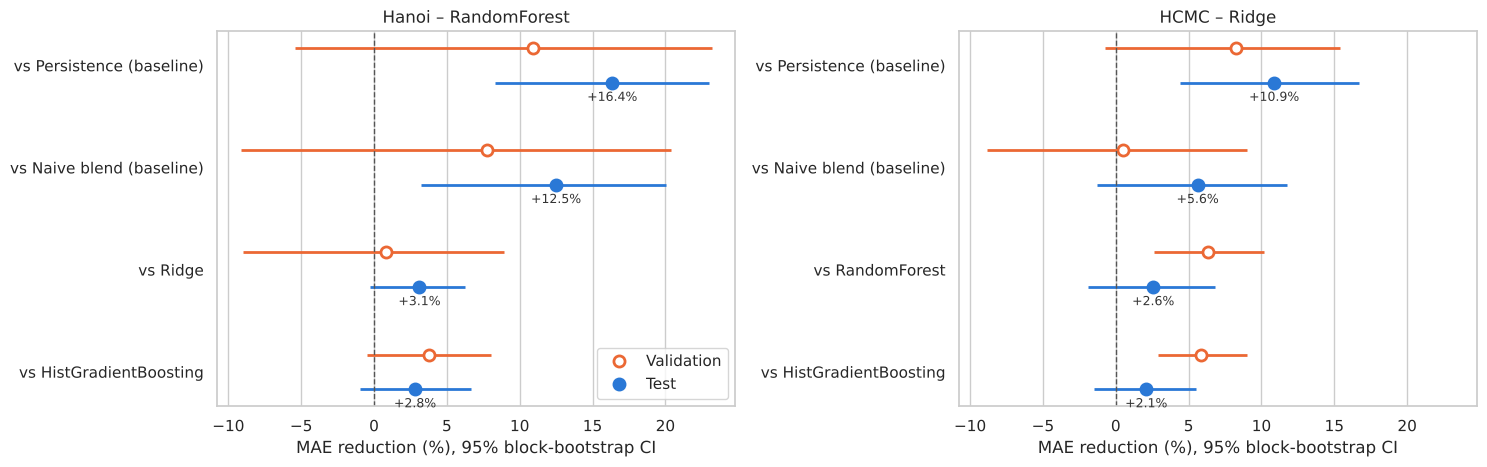

In [20]:
# Forest plot of the bootstrap confidence intervals
SET_STYLE = {'Validation': {'color': '#eb6834', 'mfc': 'white', 'offset': -0.17},   # y axis is inverted: Validation on top
             'Test': {'color': '#2a78d6', 'mfc': '#2a78d6', 'offset': 0.17}}
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), sharex=True)
for ax, city in zip(axes, CITY_FILES):
    labels = competitors(city)
    for set_name, st in SET_STYLE.items():
        sub = boot[(boot.city == city) & (boot.set == set_name)].set_index('vs').loc[labels]
        y = np.arange(len(labels)) + st['offset']
        ax.hlines(y, sub['ci_low'] * 100, sub['ci_high'] * 100, color=st['color'], lw=2)
        ax.plot(sub['gain'] * 100, y, 'o', ms=8, color=st['color'], mfc=st['mfc'], mew=2, label=set_name)
        if set_name == 'Test':
            for yi, g in zip(y, sub['gain']):
                ax.annotate(f'{g:+.1%}', (g * 100, yi), xytext=(0, -13), textcoords='offset points',
                            ha='center', fontsize=9, color='#333333')
    ax.axvline(0, color='#555555', ls='--', lw=1)
    ax.set_yticks(range(len(labels)), [f'vs {l}' for l in labels])
    ax.invert_yaxis()
    ax.set(title=f'{city} – {best_model[city]}', xlabel='MAE reduction (%), 95% block-bootstrap CI')
    ax.grid(axis='y', visible=False)
axes[0].legend(loc='lower right')
plt.tight_layout()
plt.show()

**Figure 7 caption — which differences are real?** (95% CI, 3-day blocks; *significant* = the interval excludes 0)

| City | Comparison | Validation | Test |
|---|---|---|---|
| Hanoi | RandomForest vs Persistence | +10.9% [−5.4, +23.2] | **+16.4% [+8.3, +23.0]** |
| Hanoi | RandomForest vs Naive blend | +7.8% [−9.2, +20.4] | **+12.5% [+3.2, +20.0]** |
| Hanoi | RandomForest vs Ridge | +0.8% [−9.0, +8.9] | +3.1% [−0.3, +6.3] |
| HCMC | Ridge vs Persistence | +8.2% [−0.8, +15.4] | **+10.9% [+4.4, +16.7]** |
| HCMC | Ridge vs Naive blend | +0.5% [−8.8, +9.0] | +5.6% [−1.3, +11.8] |
| HCMC | Ridge vs RandomForest | **+6.3% [+2.6, +10.1]** | +2.6% [−1.9, +6.8] |

- **Hanoi:** the gain of RandomForest over both naive baselines on Test is real (vs the Naive blend: +12.5%, CI +3.2% to +20.0%),
  and it stays positive for 1-, 3- and 7-day blocks. But RandomForest is **not** significantly better than Ridge or HGB (CIs include 0),
  and on Validation no difference is significant at all — the Validation set (1,462 samples, 29 blocks) is too small to separate
  the models, so picking RandomForest over Ridge (+0.8%) was close to a coin flip. *Machine learning helps in Hanoi; which ML model is best is not established.*
- **HCMC:** Ridge is significantly better than Persistence on Test (+10.9%), but its gain over the Naive blend (+5.6%) is **not** significant
  for any block length (the interval always reaches below 0). *We cannot claim that machine learning beats a well-chosen naive forecast in HCMC.*
  Ridge does beat both tree models significantly on Validation (≈ +6%), and in the same direction on Test (+2–3%, not significant):
  the evidence consistently says that **tree models do not help in HCMC**.
- **Method note:** an i.i.d. bootstrap over single hours would give much narrower intervals and declare almost everything significant;
  the blocks keep the strong hour-to-hour correlation of forecast errors, so the intervals are honest about how little independent evidence 3–7 months of data contain.

### 4.4. Forecast vs. actual
**Figure 8 – First 14 days of the Test set:** actual values, the Naive blend baseline and the best model of each city (chosen on Validation)
(the time axis is the **forecast** time, i.e. $t + 24h$).

Hanoi – first 14 days of Test (203 hours): MAE Naive blend 12.98 vs RandomForest 10.08 | std of forecast 8.8 vs actual 16.3 µg/m³
HCMC – first 14 days of Test (335 hours): MAE Naive blend 6.81 vs Ridge 6.96 | std of forecast 5.3 vs actual 9.5 µg/m³


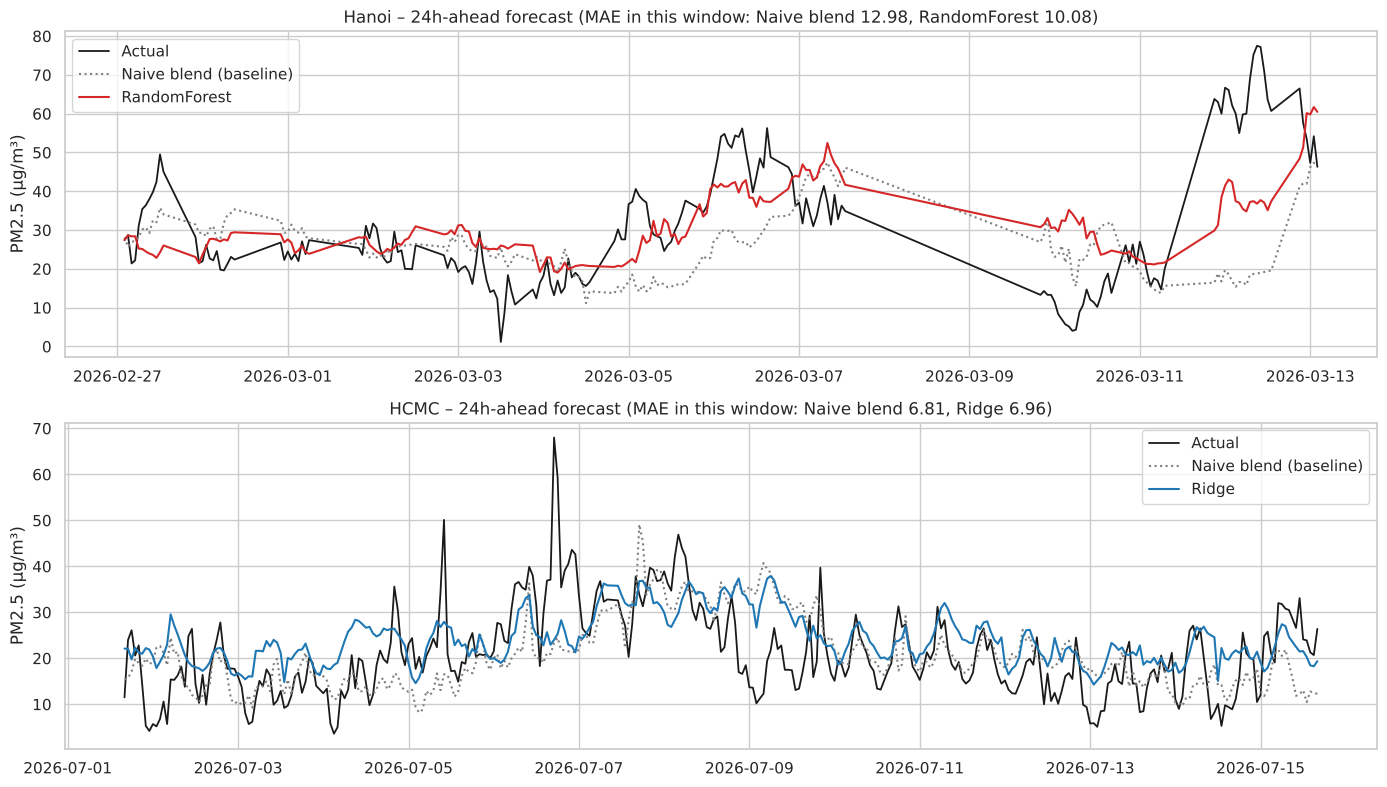

In [21]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8))
for ax, (city, f) in zip(axes, forecasters.items()):
    p = f.test_predictions
    w = p.loc[: p.index.min() + pd.Timedelta(days=14)]
    target_time = w.index + pd.Timedelta(hours=HORIZON)
    ax.plot(target_time, w['actual'], color='k', lw=1.3, label='Actual')
    ax.plot(target_time, w['Naive blend (baseline)'], color='gray', ls=':', label='Naive blend (baseline)')
    ax.plot(target_time, w[best_model[city]], color=CITY_COLORS[city], label=best_model[city])
    mae_blend = mean_absolute_error(w['actual'], w['Naive blend (baseline)'])
    mae_best = mean_absolute_error(w['actual'], w[best_model[city]])
    print(f'{city} – first 14 days of Test ({len(w)} hours): MAE Naive blend {mae_blend:.2f} vs {best_model[city]} {mae_best:.2f} | '
          f'std of forecast {w[best_model[city]].std():.1f} vs actual {w["actual"].std():.1f} µg/m³')
    ax.set(title=f'{city} – 24h-ahead forecast (MAE in this window: Naive blend {mae_blend:.2f}, {best_model[city]} {mae_best:.2f})',
           ylabel='PM2.5 (µg/m³)')
    ax.legend()
plt.tight_layout()
plt.show()

**Figure 8 caption:** In Hanoi the best model clearly tracks the actual series better than the Naive blend in this window
(MAE 10.08 vs 12.98 µg/m³ over 203 hours with data). In HCMC the two are practically tied (Ridge 6.96 vs blend 6.81 over 335 hours) —
consistent with the small overall gain in HCMC (Section 4.2). In both cities the forecast is much smoother than reality:
its standard deviation is about half of the actual one (Hanoi 8.8 vs 16.3, HCMC 5.3 vs 9.5 µg/m³), so short spikes are missed.
This is the visual counterpart of the under-forecasting of polluted hours in Section 4.5.

### 4.5. Error analysis
A regression problem has no direct confusion matrix, so we (1) analyze the error by **hour of day** and **month**, and
(2) put both the actual and the forecast PM2.5 into **concentration bands** defined by the US EPA 2024 PM2.5 breakpoints
(Good ≤ 9.0, Moderate 9.1–35.4, USG 35.5–55.4, Unhealthy 55.5–125.4, Very unhealthy and above ≥ 125.5 µg/m³) and build a
**band confusion matrix** — showing which band the model tends to confuse with which.

*Precision about the definition:* the official EPA AQI is computed from a **24-hour average** (or the NowCast for hourly reporting).
Here the breakpoints are applied to **hourly** concentrations, so these are "EPA concentration bands", **not** official AQI values.
As in the EPA rule, a concentration is first truncated to one decimal (e.g. 9.05 → 9.0 → Good) and then binned.

Hanoi: MAE by hour min 6.8 (h20) – max 9.3 (h22) | hours with < 20 Test samples (not shown): [15, 16, 19] | by month: {'2026-02': 7.6, '2026-03': 9.4, '2026-04': 7.2, '2026-05': 9.0, '2026-06': 6.8, '2026-07': 7.2, '2026-08': 6.4, '2026-09': 8.9}
HCMC: MAE by hour min 7.4 (h7) – max 9.8 (h14) | hours with < 20 Test samples (not shown): [] | by month: {'2026-07': 7.1, '2026-08': 7.7, '2026-09': 10.9}


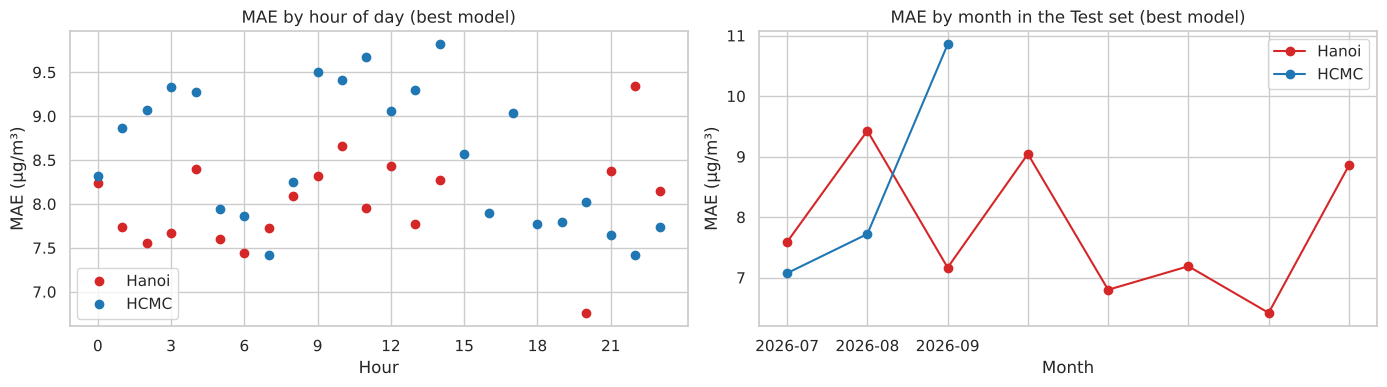

In [22]:
MIN_SAMPLES = 20   # hours/months with fewer Test samples are not shown (too noisy)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for city, f in forecasters.items():
    p = f.test_predictions
    err = (p[best_model[city]] - p['actual']).abs()
    t = p.index + pd.Timedelta(hours=HORIZON)
    hour_stats = err.groupby(t.hour).agg(['mean', 'size'])
    by_hour = hour_stats.loc[hour_stats['size'] >= MIN_SAMPLES, 'mean']
    by_month = err.groupby(t.strftime('%Y-%m')).agg(['mean', 'size']).query('size >= @MIN_SAMPLES')['mean']
    by_hour.plot(ax=axes[0], marker='o', ls='', color=CITY_COLORS[city], label=city)
    by_month.plot(ax=axes[1], marker='o', color=CITY_COLORS[city], label=city)
    sparse = hour_stats.index[hour_stats['size'] < MIN_SAMPLES].tolist()
    print(f'{city}: MAE by hour min {by_hour.min():.1f} (h{by_hour.idxmin()}) – max {by_hour.max():.1f} '
          f'(h{by_hour.idxmax()}) | hours with < {MIN_SAMPLES} Test samples (not shown): {sparse} '
          f'| by month: {by_month.round(1).to_dict()}')
axes[0].set(title='MAE by hour of day (best model)', xlabel='Hour', ylabel='MAE (µg/m³)', xticks=range(0, 24, 3))
axes[1].set(title='MAE by month in the Test set (best model)', xlabel='Month', ylabel='MAE (µg/m³)')
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()

Hanoi: correct EPA band 80.7% | within ±1 band: 98.4%
Predicted        Good  Moderate  USG  Unhealthy  Very unhealthy+
Actual                                                          
Good                0        35    0          0                0
Moderate            0      1127   45          5                0
USG                 0       148   68         13                0
Unhealthy           0        18   22          0                0
Very unhealthy+     0         0    0          0                0

HCMC: correct EPA band 76.3% | within ±1 band: 98.6%
Predicted        Good  Moderate  USG  Unhealthy  Very unhealthy+
Actual                                                          
Good                0        80    0          0                0
Moderate            0      1593   81          0                0
USG                 0       286   71          2                0
Unhealthy           0        29   38          4                0
Very unhealthy+     0         1    0          0

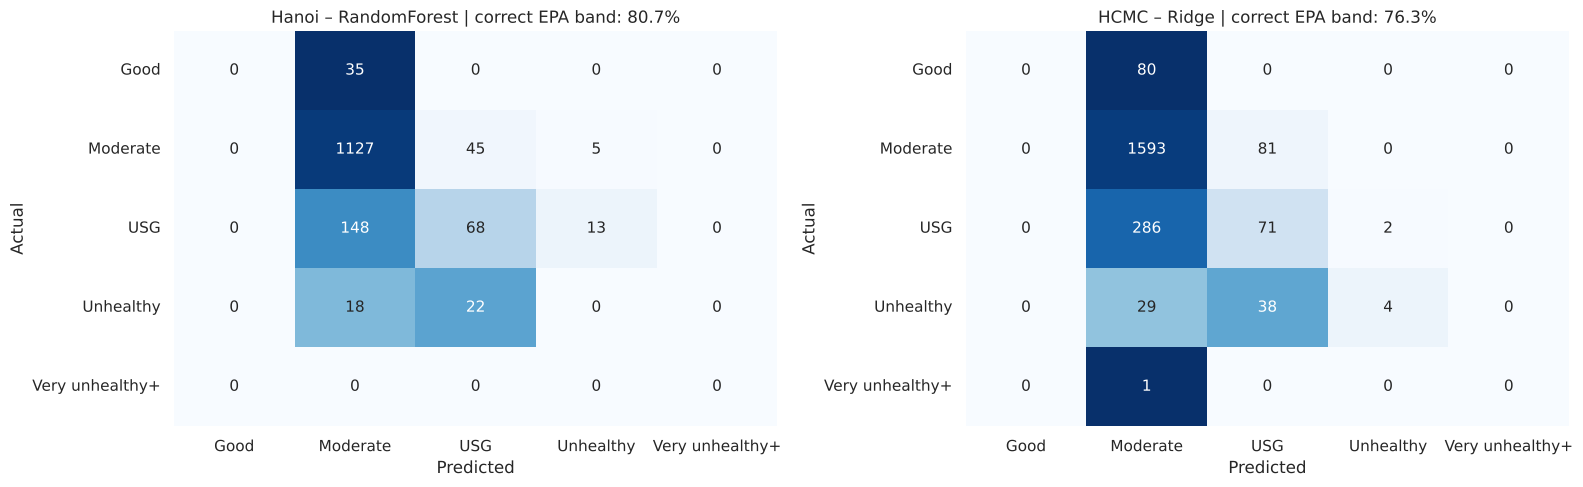

In [23]:
EPA_BINS = [-np.inf, 9.0, 35.4, 55.4, 125.4, np.inf]      # right-closed: (-inf, 9.0], (9.0, 35.4], ...
EPA_LABELS = ['Good', 'Moderate', 'USG', 'Unhealthy', 'Very unhealthy+']


def to_epa_band(values):
    """Truncate to 0.1 µg/m³ (EPA rule), then map each hourly PM2.5 value to its EPA concentration band."""
    truncated = np.floor(np.asarray(values, dtype=float) * 10) / 10
    return pd.cut(pd.Series(truncated), bins=EPA_BINS, labels=EPA_LABELS)


fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, (city, f) in zip(axes, forecasters.items()):
    p = f.test_predictions
    actual_lvl, pred_lvl = to_epa_band(p['actual']), to_epa_band(p[best_model[city]])
    cm = pd.crosstab(actual_lvl, pred_lvl, rownames=['Actual'], colnames=['Predicted'], dropna=False)
    cm = cm.reindex(index=EPA_LABELS, columns=EPA_LABELS, fill_value=0)
    cm_norm = cm.div(cm.sum(axis=1).replace(0, np.nan), axis=0).fillna(0)
    sns.heatmap(cm_norm, annot=cm.values, fmt='d', cmap='Blues', cbar=False, ax=ax)
    acc = (actual_lvl == pred_lvl).mean()
    ax.set_title(f'{city} – {best_model[city]} | correct EPA band: {acc:.1%}')
    print(f'{city}: correct EPA band {acc:.1%} | within ±1 band: '
          f'{(abs(actual_lvl.cat.codes - pred_lvl.cat.codes) <= 1).mean():.1%}')
    print(cm, end='\n\n')
plt.tight_layout()
plt.show()

*USG = Unhealthy for Sensitive Groups (35.5–55.4 µg/m³).*


**Error analysis findings:**
- **By hour:** Hanoi's error is fairly even across the hours that have data (6.8–9.3 µg/m³; hours 15h, 16h and 19h have fewer than 20 Test samples
  and are not shown). HCMC's error is highest during the daytime (peak 9.8 at 14h) and lowest at the 7h rush hour (7.4).
- **By month:** the error grows towards the end of the Test period in HCMC (7.1 in July → 10.9 in September 2026), as pollution starts rising again.
  The model learned mostly from the earlier distribution, so it reacts slowly to seasonal change. Hanoi varies between 6.4 (August) and 9.4 (March).
- **By EPA concentration band:** the correct band is predicted for 80.7% (Hanoi) and 76.3% (HCMC) of hours; 98.4% / 98.6% are within ±1 band.
  The main error is **under-forecasting polluted hours**: in HCMC, 286 of 359 "USG" hours are predicted as "Moderate"; in Hanoi 148 of 229 "USG" hours,
  and none of the 40 "Unhealthy" hours in Hanoi is predicted correctly. The model never predicts "Good", i.e. it pulls forecasts towards the mean
  (the expected behaviour of a model trained to minimize MAE).
- **Practical consequence:** the model is useful for following the general trend, but **not yet reliable as an early-warning tool for severe pollution episodes** —
  a case where a missed alarm costs more than a false alarm.

### 4.6. Feature importance (permutation importance)
Measures how much the Test MAE increases when each original feature of the best model is randomly shuffled.
*Caveat:* the PM2.5 lag/rolling features are strongly correlated, so shuffling one of them hurts less than its real
contribution (the others carry the same information) — the importance of the "PM2.5 history" group is spread over several features.

Hanoi – top 5: {'wind_speed_10m': 0.1, 'pm25_lag_0': 0.06, 'day_of_week': 0.06, 'temperature_2m': 0.04, 'surface_pressure': 0.04}


HCMC – top 5: {'pm25_lag_0': 0.98, 'temperature_2m': 0.86, 'hour_cos': 0.33, 'wind_speed_10m': 0.29, 'relative_humidity_2m': 0.16}


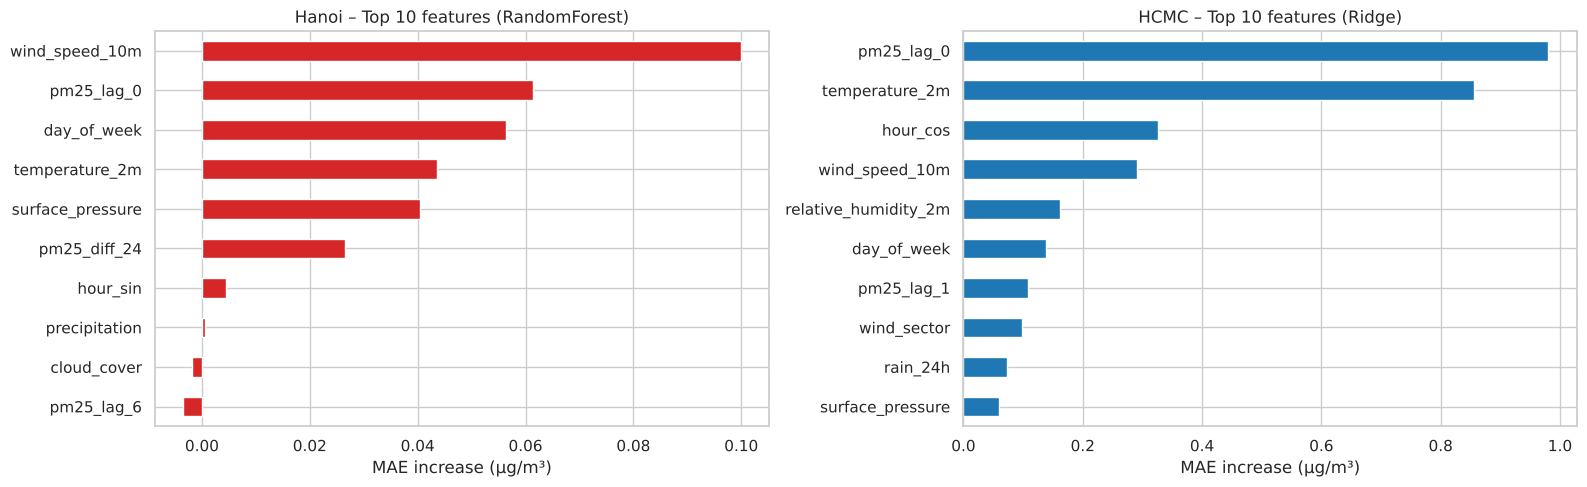

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, (city, f) in zip(axes, forecasters.items()):
    model = f.models[best_model[city]]
    imp = permutation_importance(model, f.test[FEATURES], f.test[TARGET], n_repeats=5,
                                 scoring='neg_mean_absolute_error', random_state=RANDOM_STATE)
    s = pd.Series(imp.importances_mean, index=FEATURES).nlargest(10).sort_values()
    s.plot.barh(ax=ax, color=CITY_COLORS[city])
    print(f'{city} – top 5:', s[::-1].head(5).round(2).to_dict())
    ax.set(title=f'{city} – Top 10 features ({best_model[city]})', xlabel='MAE increase (µg/m³)')
plt.tight_layout()
plt.show()

Because single-feature importance is diluted by correlated features, we also shuffle **whole groups** of features together
(grouped permutation importance): PM2.5 history, weather (including wind sector) and calendar (hour, season, day of week).

In [25]:
FEATURE_GROUPS = {'PM2.5 history': PM_FEATURES,
                  'Weather': WEATHER_FEATURES + ['wind_sector'],
                  'Calendar': CYCLIC_FEATURES + ['season', 'day_of_week']}


def group_importance(model, X, y, groups, n_repeats=10, seed=RANDOM_STATE):
    """Mean MAE increase when all columns of a group are shuffled together (same row permutation)."""
    rng = np.random.default_rng(seed)
    base = mean_absolute_error(y, model.predict(X))
    result = {}
    for name, cols in groups.items():
        deltas = []
        for _ in range(n_repeats):
            Xs = X.copy()
            Xs[cols] = X[cols].values[rng.permutation(len(X))]
            deltas.append(mean_absolute_error(y, model.predict(Xs)) - base)
        result[name] = np.mean(deltas)
    return result


group_imp = pd.DataFrame({city: group_importance(f.models[best_model[city]], f.test[FEATURES], f.test[TARGET], FEATURE_GROUPS)
                          for city, f in forecasters.items()})
print('Grouped importance (MAE increase, µg/m³):', group_imp.round(2).to_dict())
display(group_imp.round(2))

Grouped importance (MAE increase, µg/m³): {'Hanoi': {'PM2.5 history': 0.78, 'Weather': 0.47, 'Calendar': 0.01}, 'HCMC': {'PM2.5 history': 1.81, 'Weather': 0.9, 'Calendar': 0.47}}


,Hanoi,HCMC
PM2.5 history,0.78,1.81
Weather,0.47,0.90
Calendar,0.01,0.47


**Findings:**
- **HCMC (Ridge):** the current PM2.5 level (`pm25_lag_0`, +0.98 µg/m³) and **temperature** (+0.86) matter most, followed by the **hour of day**
  (`hour_cos`) and **wind speed**. By group: PM2.5 history +1.81, weather +0.90, calendar +0.47 — HCMC's dust follows the daily traffic rhythm
  and how well the wind disperses it, consistent with the EDA (7h peak, strongest correlation with wind).
- **Hanoi (RandomForest):** single-feature importances are all small (≤ 0.11 µg/m³, led by wind speed and the current PM2.5),
  because the model spreads the PM2.5 information over many correlated lag/rolling features. The grouped importance shows the real picture:
  **PM2.5 history +0.78, weather +0.47, calendar ≈ 0**. The calendar (season) carries no signal on this Test period, which covers only the end of winter.
  Small single-feature values such as `day_of_week` should be read as noise.

The drivers differ between the cities (HCMC: daily cycle + temperature/wind; Hanoi: recent PM2.5 + weather), which is further evidence that each city should
have its own model.

### 4.7. Inference demo: `predict_next`
Takes the hourly observation history up to time $t$ and returns the PM2.5 forecast at $t + 24h$ together with its EPA concentration band.
Demo: we use a history ending 24 hours before the last available observation, then compare with the known actual value.

In [26]:
def predict_next(city, history):
    """history: hourly DataFrame (same columns as the cleaned data), ending at time t."""
    model = forecasters[city].models[best_model[city]]
    x_last = build_features(history, city).iloc[[-1]]
    value = float(model.predict(x_last[FEATURES])[0])
    return {'city': city, 'model': best_model[city],
            'forecast_time': x_last.index[0] + pd.Timedelta(hours=HORIZON),
            'pm25_forecast': round(value, 1), 'epa_band': str(to_epa_band([value])[0])}


demo_rows = []
for city, df in clean.items():
    t_end = df['pm25_raw'].last_valid_index() - pd.Timedelta(hours=HORIZON)
    history = df.loc[t_end - pd.Timedelta(days=7): t_end]
    res = predict_next(city, history)
    actual = df.loc[res['forecast_time'], 'pm25_raw']
    res.update({'pm25_actual': round(float(actual), 1), 'epa_band_actual': str(to_epa_band([actual])[0])})
    demo_rows.append(res)
display(pd.DataFrame(demo_rows))

,city,model,forecast_time,pm25_forecast,epa_band,pm25_actual,epa_band_actual
0,Hanoi,RandomForest,2026-09-30 08:00:00,22.5,Moderate,17.5,Moderate
1,HCMC,Ridge,2026-09-30 22:00:00,34.6,Moderate,44.5,USG


### 4.8. Conclusions, limitations and future work


**Conclusions:**
- We built a 24h-ahead PM2.5 forecasting pipeline, applied identically but **trained independently** for Hanoi and HCMC, using real
  monitoring data from OpenAQ combined with Open-Meteo weather (12/2024 – 09/2026). Features use only data available at forecast time
  (causal forward-fill), and models are evaluated only on measured values.
- On the Test set, the best model (chosen on Validation) lowers MAE by **12.5% in Hanoi (RandomForest)** and **5.6% in HCMC (Ridge)** compared with the
  strongest naive baseline (Naive blend), or by 16.4% / 10.9% compared with Persistence, and predicts the correct EPA concentration band in 76–81% of hours.
- Block-bootstrap confidence intervals show that the Hanoi gain over the Naive blend is real (95% CI +3.2% to +20.0%), while the HCMC gain
  over the Naive blend is not significant (−1.3% to +11.8%); in HCMC, tree models are significantly worse than Ridge on Validation.
  Which ML model is best in Hanoi is not established (RandomForest vs Ridge: CI includes 0).

**Limitations:**
- Only **one station** per city. The HCMC station is a low-cost sensor (AirGradient) that may be less accurate at high humidity.
- Hanoi has a lot of missing data (32.8%, and 31–97% per month from November 2025), so its Validation/Test sets are small, contain almost no afternoon hours,
  and the Test set covers only the end of winter.
- Only 22 months of data (fewer than 2 seasonal cycles), so seasonal patterns are hard to learn.
- The Validation sets are too small for the block bootstrap to separate the ML models, so the model selection itself is uncertain (Section 4.3).
- The models under-forecast high-pollution episodes. Weather features use observations at $t$, not weather forecasts for $t+24h$.

**Future work:**
- Add **weather forecasts** for the target time and data from more stations in each city.
- Use quantile regression / sample weights that emphasize high-pollution hours, or add an "exceeds threshold or not" classifier for early warning.
- Collect a longer history so that Validation can separate the models, and use the same calendar split for both cities.
- Try dedicated time series models (SARIMAX, multi-horizon LightGBM, LSTM) once longer data is available.